# 00 — Data Preparation and Initial Exploration

**Project:** Algorithmic Fairness in Computer Vision

This notebook takes the project from raw data to a validated, reproducible master annotation table, ready for the later Phase 1 fairness audit. It performs structural exploration, integrity checking, label validation, duplicate checking, and preprocessing pilots — it does **not** calculate confirmatory fairness results.

Reusable logic lives in `src/*.py`; this notebook orchestrates those functions, displays results, and records decisions.

## 1. Purpose and Frozen Settings

### Purpose

This stage answers: *"What exactly is in these datasets, is it valid, and is the preprocessing pipeline trustworthy?"* It does not search for the largest demographic disparity, and it does not calculate equalised-odds gaps, demographic parity gaps, TPR/FPR fairness comparisons, "most biased subgroup" claims, or statistical significance of demographic model-performance differences. Those belong to the later confirmatory audit.

### Datasets expected

- **LFW** — `data/LFW/lfw/lfw/<identity>/` (original, unaligned), plus official protocol files (`people.csv`, `pairs.csv`, `matchpairsDev*.csv`, `mismatchpairsDev*.csv`). No demographic metadata file is supplied for LFW. **2026-09-15 (Task 2 resolved):** switched from the deep-funneled variant to the original unaligned images, downloaded via a Figshare mirror after `vis-www.cs.umass.edu` failed to resolve from this network on two separate days; MD5 checksum verified exactly against the official value documented in `torchvision.datasets.lfw`. See `metadata/acquisition_manifest.csv` and `docs/limitations_draft.md` (published LFW accuracy figures mostly use deep-funneled, so results here are not directly comparable to the literature).
- **UTKFace** — `data/UTKFace/` contains four folders, but only **one is canonical**: `UTKFace/UTKFace/` (23,708 images, matching the officially published UTKFace count exactly). `UTKFace/crop_part1/`, `UTKFace/utkface_aligned_cropped/UTKFace/`, and `UTKFace/utkface_aligned_cropped/crop_part1/` are all duplicate locations. **2026-09-14 correction:** `crop_part1/` was originally (incorrectly) treated as canonical alongside `UTKFace/UTKFace/`, inflating the canonical count by 9,780. SHA-256 hashing showed 9,779/9,780 of its files are byte-identical to files already in `UTKFace/UTKFace/` (the one exception appears to be the same photo re-labelled with a different gender/race code). See `src/data_inventory.py` and the Task 5 reconciliation in Section 8 for the evidence.

This notebook does not assume the above is exhaustive or unchanged — Section 3 re-scans `data/` recursively and reports what is actually present.

### Frozen settings (source of truth: `configs/GOV-002_categories.yaml`, `configs/GOV-004_statistics.yaml`)

- **Random seed:** `26041`
- **Gender coding:** `female = 1`, `male = 0`, `unknown = null` — a coding convention only, not a value judgement.
- **Fine age bands:** `0-2, 3-9, 10-19, 20-29, 30-39, 40-49, 50-59, 60-69, 70+`
- **Coarse age bands:** `0-19, 20-39, 40-59, 60+` — every fine band nests inside exactly one coarse band (verified in Section 6).
- **Age band usage:** fine for composition, single-axis, and two-way intersections; coarse for three-way intersections.
- **Race handling:** native FairFace and UTKFace race labels are kept as-is; LFW race stays `unknown` (no approved source supplied); race is never directly compared across datasets — cross-dataset comparison prefers ITA, `L*`, hue, gender, and image-quality measures.
- **Unknown-label policy:** missing demographic values stay `unknown`/`NaN`. They are never coerced into `0`, `male`, `female`, a race category, or an age band.
- **Raw-data immutability:** everything under `data/` as currently laid out is treated as read-only. All generated files go under `outputs/data_prep/` and `data/processed/`.

### Descriptive preparation vs. confirmatory fairness testing

This notebook is **descriptive and structural**: it inventories, validates, and organises data. Any later comparison of model error rates across demographic groups, or any claim about which subgroup is disadvantaged, belongs to the separate Phase 1 confirmatory audit (governed by `configs/GOV-004_statistics.yaml`), which freezes its statistical tests before viewing results. Mixing the two stages would let this exploratory pass quietly shape the confirmatory analysis — so nothing here should be read as a fairness finding.

The frozen settings above are loaded programmatically (not retyped) in Section 2 below, and saved to `outputs/data_prep/config/data_prep_config.yaml` as this pipeline's own record.

## 2. Imports and Paths

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise RuntimeError(f"Could not locate project root above {start}")


PROJECT_ROOT = _find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision


In [2]:
import datetime
import json
import platform

import numpy
import pandas
import PIL
import yaml

from src import paths

paths.ensure_output_dirs()

optional_packages = {}
for _name in ["cv2", "skimage", "imagehash", "pyarrow", "torch"]:
    try:
        _mod = __import__(_name)
        optional_packages[_name] = getattr(_mod, "__version__", "unknown")
    except ImportError:
        optional_packages[_name] = None

environment_info = {
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "processor": platform.processor(),
    "packages": {
        "pandas": pandas.__version__,
        "numpy": numpy.__version__,
        "pillow": PIL.__version__,
        "pyyaml": yaml.__version__,
        **optional_packages,
    },
    "gpu_available": optional_packages.get("torch") is not None,
}

print(json.dumps(environment_info, indent=2))

with open(paths.OUTPUTS_DATA_PREP_DIR / "logs" / "environment_info.json", "w") as f:
    json.dump(environment_info, f, indent=2)

{
  "python_version": "3.11.9",
  "platform": "Windows-10-10.0.26200-SP0",
  "processor": "Intel64 Family 6 Model 140 Stepping 1, GenuineIntel",
  "packages": {
    "pandas": "3.0.5",
    "numpy": "2.4.6",
    "pillow": "12.3.0",
    "pyyaml": "6.0.3",
    "cv2": "5.0.0",
    "skimage": "0.26.0",
    "imagehash": "4.3.2",
    "pyarrow": "25.0.1",
    "torch": null
  },
  "gpu_available": false
}


`cv2`, `skimage`, `imagehash`, and `pyarrow` are installed locally and used from Section 8 onward. `torch` (needed for the RetinaFace pilot in Section 12) is intentionally **not** installed locally — that pilot is deferred to the Wits cluster, where GPU compute is available; this notebook records it as `null`/blocked rather than skipping the record entirely.

In [3]:
with open(paths.CONFIGS_DIR / "GOV-002_categories.yaml") as f:
    gov002 = yaml.safe_load(f)

with open(paths.CONFIGS_DIR / "GOV-004_statistics.yaml") as f:
    gov004 = yaml.safe_load(f)

random_seed = gov004["bootstrap"]["seed"]
gender_codes = gov002["gender"]["codes"]
age_bands_fine = [b["name"] for b in gov002["age_bands_fine"]]
age_bands_coarse = [b["name"] for b in gov002["age_bands_coarse"]]
race_policy = gov002["race"]

print("Random seed:", random_seed)
print("Gender codes:", gender_codes)
print("Fine age bands:", age_bands_fine)
print("Coarse age bands:", age_bands_coarse)
print("Race policy:", json.dumps(race_policy, indent=2))

Random seed: 26041
Gender codes: {'female': 1, 'male': 0, 'unknown': None}
Fine age bands: ['0-2', '3-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70+']
Coarse age bands: ['0-19', '20-39', '40-59', '60+']
Race policy: {
  "within_dataset_only": true,
  "direct_cross_dataset_comparison": false,
  "native_available": [
    "fairface",
    "utkface"
  ],
  "derived_only": [
    "lfw"
  ],
  "cross_dataset_axes_allowed": [
    "ITA",
    "L_star",
    "hue_angle",
    "gender",
    "image_quality_measures"
  ]
}


In [4]:
dataset_roots = {
    "fairface": paths.DATA_DIR / "FairFace",
    "lfw": paths.DATA_DIR / "LFW",
    "utkface": paths.DATA_DIR / "UTKFace",
}

datasets_detected = {name: root.exists() for name, root in dataset_roots.items()}
for name, present in datasets_detected.items():
    print(f"{name}: {'found' if present else 'MISSING'} ({dataset_roots[name]})")

fairface: found (C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\data\FairFace)
lfw: found (C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\data\LFW)
utkface: found (C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\data\UTKFace)


In [5]:
data_prep_config = {
    "meta": {
        "issue": "DATA-PREP-PHASE0",
        "purpose": (
            "Data preparation and initial exploration pipeline for the "
            "Algorithmic Fairness in Computer Vision project. Produces a "
            "validated, reproducible master annotation table from raw LFW, "
            "FairFace and UTKFace data, ready for the later Phase 1 fairness "
            "audit. This stage does not calculate confirmatory fairness "
            "results."
        ),
        "references": {
            "categories": "configs/GOV-002_categories.yaml",
            "statistics": "configs/GOV-004_statistics.yaml",
            "preprocessing": "configs/GOV-006_preprocessing.yaml",
            "exclusions": "configs/GOV-007_exclusions.yaml",
        },
        "generated": datetime.date.today().isoformat(),
    },
    "random_seed": random_seed,
    "gender_codes": gender_codes,
    "age_bands_fine": age_bands_fine,
    "age_bands_coarse": age_bands_coarse,
    "race_policy": {
        "within_dataset_only": race_policy["within_dataset_only"],
        "native_available": race_policy["native_available"],
        "derived_only": race_policy["derived_only"],
    },
    "unknown_label_policy": {
        "missing_demographic_label": "unknown",
        "never_infer_sensitive_attributes_from_image": True,
        "never_convert_missing_to_a_real_category": True,
    },
    "raw_data_immutability": True,
    "datasets_detected": datasets_detected,
    "dataset_paths": {
        "fairface": {
            "root": "data/FairFace",
            "splits": ["train", "val"],
        },
        "lfw": {
            "root": "data/LFW",
            "image_root": "data/LFW/lfw/lfw",
            "variant": "original (unaligned)",
            "note": (
                "Task 2 resolved 2026-09-15: switched from deep-funneled to "
                "original unaligned LFW so the project's own detection/"
                "alignment stage can be audited. Downloaded via a Figshare "
                "mirror (vis-www.cs.umass.edu did not resolve on 2026-09-14 "
                "or 2026-09-15); MD5 verified exactly against the official "
                "checksum. See metadata/acquisition_manifest.csv and "
                "docs/limitations_draft.md."
            ),
        },
        "utkface": {
            "root": "data/UTKFace",
            "canonical_dirs": [
                "data/UTKFace/UTKFace",
            ],
            "duplicate_dirs": [
                "data/UTKFace/crop_part1",
                "data/UTKFace/utkface_aligned_cropped/UTKFace",
                "data/UTKFace/utkface_aligned_cropped/crop_part1",
            ],
            "note": (
                "CORRECTED 2026-09-14 (Task 5 reconciliation): crop_part1 was "
                "originally treated as canonical alongside UTKFace/UTKFace, "
                "inflating the canonical count by 9,780. SHA-256 hashing "
                "confirmed 9,779/9,780 of its files are byte-identical to "
                "files already in UTKFace/UTKFace. Official UTKFace is "
                "published as 23,708 images, matching UTKFace/UTKFace alone. "
                "All three of crop_part1 and both utkface_aligned_cropped/* "
                "subfolders are duplicate locations."
            ),
        },
    },
    "output_paths": {
        "outputs_root": "outputs/data_prep",
        "processed_data_root": "data/processed",
    },
}

config_path = paths.OUTPUTS_DATA_PREP_DIR / "config" / "data_prep_config.yaml"
with open(config_path, "w") as f:
    yaml.safe_dump(data_prep_config, f, sort_keys=False)

print("Saved:", config_path)

Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\config\data_prep_config.yaml


Sections 1 and 2 complete. Frozen settings are loaded from GOV-002/GOV-004 and saved to `outputs/data_prep/config/data_prep_config.yaml`; environment info is logged to `outputs/data_prep/logs/environment_info.json`.

**Next:** Section 3 — Dataset Loading (recursive inventory of `data/`, then metadata loading), using `src/data_inventory.py` and `src/metadata_parsers.py`.

## 3. Dataset Loading

### 3.1 Dataset source and version

Recorded per dataset below: detected path, source/version information (marked `unknown` where no README/version file exists, rather than guessed), metadata files found, image directories, and scan date. See `src/data_inventory.py::build_dataset_inventory`.

In [6]:
from src import data_inventory

DATASET_DIRS = {"fairface": "FairFace", "lfw": "LFW", "utkface": "UTKFace"}

LOCATIONS = {
    ("fairface", "train"): "FairFace/train",
    ("fairface", "val"): "FairFace/val",
    ("lfw", "lfw_root_all"): "LFW",
    ("utkface", "crop_part1_dup"): "UTKFace/crop_part1",
    ("utkface", "aligned_UTKFace_dup"): "UTKFace/utkface_aligned_cropped/UTKFace",
    ("utkface", "aligned_crop_part1_dup"): "UTKFace/utkface_aligned_cropped/crop_part1",
}

dataset_inventory_df = data_inventory.build_dataset_inventory(paths.DATA_DIR, DATASET_DIRS)

inventory_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "dataset_inventory.csv"
dataset_inventory_df.to_csv(inventory_path, index=False)
print("Saved:", inventory_path)
dataset_inventory_df

Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\dataset_inventory.csv


,dataset,detected_path,exists,date_scanned,provenance_files_found,n_provenance_files,metadata_files_found,n_metadata_files,n_image_directories,image_directories_sample,all_files,image_files,metadata_files,other_files,directories
0,fairface,C:\Users\User1\projects\Algorithmic Fairness i...,True,2026-09-18,none found,0,train_labels.csv; val_labels.csv,2,2,train; val,97701,97698,2,1,2
1,lfw,C:\Users\User1\projects\Algorithmic Fairness i...,True,2026-09-18,none found,0,lfw_allnames.csv; lfw_readme.csv; matchpairsDe...,10,11498,lfw-deepfunneled\lfw-deepfunneled\AJ_Cook; lfw...,26478,26466,10,2,11502
2,utkface,C:\Users\User1\projects\Algorithmic Fairness i...,True,2026-09-18,none found,0,none found,0,4,UTKFace; crop_part1; utkface_aligned_cropped\U...,66977,66976,0,1,5


### 3.2 Dataset file inventory

One row per named sub-location (not just per dataset), so the four overlapping UTKFace folders and LFW's image tree vs. metadata root are counted separately. See `src/data_inventory.py::build_file_inventory`.

In [7]:
file_inventory_df = data_inventory.build_file_inventory(paths.DATA_DIR, LOCATIONS)

file_inventory_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "file_inventory.csv"
file_inventory_df.to_csv(file_inventory_path, index=False)
print("Saved:", file_inventory_path)
file_inventory_df

Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\file_inventory.csv


,dataset,location,path,exists,all_files,image_files,metadata_files,other_files,directories,identities
0,fairface,train,C:\Users\User1\projects\Algorithmic Fairness i...,True,86744,86744,0,0,0,0
1,fairface,val,C:\Users\User1\projects\Algorithmic Fairness i...,True,10954,10954,0,0,0,0
2,lfw,lfw_root_all,C:\Users\User1\projects\Algorithmic Fairness i...,True,26478,26466,10,2,11502,2
3,lfw,lfw_images,C:\Users\User1\projects\Algorithmic Fairness i...,True,13233,13233,0,0,5749,5749
4,lfw,lfw_deepfunneled,C:\Users\User1\projects\Algorithmic Fairness i...,True,13233,13233,0,0,5749,5749
5,utkface,UTKFace_raw,C:\Users\User1\projects\Algorithmic Fairness i...,True,23708,23708,0,0,0,0
6,utkface,crop_part1_dup,C:\Users\User1\projects\Algorithmic Fairness i...,True,9780,9780,0,0,0,0
7,utkface,aligned_UTKFace_dup,C:\Users\User1\projects\Algorithmic Fairness i...,True,23708,23708,0,0,0,0
8,utkface,aligned_crop_part1_dup,C:\Users\User1\projects\Algorithmic Fairness i...,True,9780,9780,0,0,0,0


### 3.3 Load metadata

**FairFace** — official CSVs loaded as-is, original columns preserved.

In [8]:
from src import metadata_parsers

fairface_train = metadata_parsers.load_fairface_labels(
    paths.DATA_DIR / "FairFace" / "train_labels.csv", split="train"
)
fairface_val = metadata_parsers.load_fairface_labels(
    paths.DATA_DIR / "FairFace" / "val_labels.csv", split="val"
)
fairface_labels = pandas.concat([fairface_train, fairface_val], ignore_index=True)

interim_dir = paths.PROCESSED_DATA_DIR / "interim"
interim_dir.mkdir(parents=True, exist_ok=True)
fairface_labels.to_parquet(interim_dir / "fairface_labels.parquet", index=False)

print("FairFace labels shape:", fairface_labels.shape)
print("Columns:", list(fairface_labels.columns))
fairface_labels.head()

FairFace labels shape: (97698, 7)
Columns: ['file', 'age', 'gender', 'race', 'service_test', 'split', 'metadata_source']


,file,age,gender,race,service_test,split,metadata_source
0,train/1.jpg,50-59,Male,East Asian,True,train,C:\Users\User1\projects\Algorithmic Fairness i...
1,train/2.jpg,30-39,Female,Indian,False,train,C:\Users\User1\projects\Algorithmic Fairness i...
2,train/3.jpg,3-9,Female,Black,False,train,C:\Users\User1\projects\Algorithmic Fairness i...
3,train/4.jpg,20-29,Female,Indian,True,train,C:\Users\User1\projects\Algorithmic Fairness i...
4,train/5.jpg,20-29,Female,Indian,True,train,C:\Users\User1\projects\Algorithmic Fairness i...


**LFW** — protocol files loaded as-is; the identity/image table is built from the folder structure (no demographic label is inferred from name or image).

In [9]:
lfw_people = metadata_parsers.load_lfw_people(paths.DATA_DIR / "LFW" / "people.csv")
lfw_pairs = metadata_parsers.load_lfw_pairs(paths.DATA_DIR / "LFW" / "pairs.csv")

lfw_people.to_parquet(interim_dir / "lfw_people.parquet", index=False)
lfw_pairs.to_parquet(interim_dir / "lfw_pairs.parquet", index=False)

print("lfw_people shape:", lfw_people.shape)
print("lfw_pairs shape:", lfw_pairs.shape)
print(
    "Other LFW protocol files present but not yet loaded (deferred to Section 14 "
    "- LFW protocol/View1/View2): peopleDevTrain.csv, peopleDevTest.csv, "
    "matchpairsDevTrain.csv, matchpairsDevTest.csv, mismatchpairsDevTrain.csv, "
    "mismatchpairsDevTest.csv, lfw_allnames.csv"
)
lfw_people.head()

lfw_people shape: (5758, 3)
lfw_pairs shape: (6000, 5)
Other LFW protocol files present but not yet loaded (deferred to Section 14 - LFW protocol/View1/View2): peopleDevTrain.csv, peopleDevTest.csv, matchpairsDevTrain.csv, matchpairsDevTest.csv, mismatchpairsDevTrain.csv, mismatchpairsDevTest.csv, lfw_allnames.csv


,name,images,metadata_source
0,Abdel_Madi_Shabneh,1.0,C:\Users\User1\projects\Algorithmic Fairness i...
1,Abdul_Rahman,1.0,C:\Users\User1\projects\Algorithmic Fairness i...
2,Abel_Pacheco,4.0,C:\Users\User1\projects\Algorithmic Fairness i...
3,Adriana_Lima,1.0,C:\Users\User1\projects\Algorithmic Fairness i...
4,Afton_Smith,1.0,C:\Users\User1\projects\Algorithmic Fairness i...


In [10]:
lfw_image_root = paths.DATA_DIR / "LFW" / "lfw" / "lfw"
lfw_identity_table = metadata_parsers.build_lfw_identity_table(lfw_image_root)
lfw_identity_table.to_parquet(interim_dir / "lfw_identity_table.parquet", index=False)

print("LFW identity table shape:", lfw_identity_table.shape)
print("Unique identities:", lfw_identity_table["identity"].nunique())
print("Total images:", len(lfw_identity_table))
lfw_identity_table.head()

LFW identity table shape: (13233, 5)
Unique identities: 5749
Total images: 13233


,identity,image_num,original_path,subject_id,images_per_identity
0,Aaron_Eckhart,1,LFW/lfw/lfw/Aaron_Eckhart/Aaron_Eckhart_0001.jpg,Aaron_Eckhart,1
1,Aaron_Guiel,1,LFW/lfw/lfw/Aaron_Guiel/Aaron_Guiel_0001.jpg,Aaron_Guiel,1
2,Aaron_Patterson,1,LFW/lfw/lfw/Aaron_Patterson/Aaron_Patterson_00...,Aaron_Patterson,1
3,Aaron_Peirsol,1,LFW/lfw/lfw/Aaron_Peirsol/Aaron_Peirsol_0001.jpg,Aaron_Peirsol,4
4,Aaron_Peirsol,2,LFW/lfw/lfw/Aaron_Peirsol/Aaron_Peirsol_0002.jpg,Aaron_Peirsol,4


**UTKFace** — no metadata file exists; age/gender/race are encoded in each filename and parsed defensively (malformed filenames are flagged, not dropped). Only the two canonical locations (`UTKFace/`, `crop_part1/`) are parsed here — the two duplicate `utkface_aligned_cropped/*` locations are excluded from the metadata table per the Section 1 decision, pending Section 9 confirmation.

In [11]:
utkface_main = metadata_parsers.load_utkface_directory(
    paths.DATA_DIR / "UTKFace" / "UTKFace", location_label="UTKFace_raw"
)
utkface_crop_part1 = metadata_parsers.load_utkface_directory(
    paths.DATA_DIR / "UTKFace" / "crop_part1", location_label="crop_part1_raw"
)
utkface_parsed = pandas.concat([utkface_main, utkface_crop_part1], ignore_index=True)
utkface_parsed.to_parquet(interim_dir / "utkface_parsed.parquet", index=False)

print("UTKFace parsed shape:", utkface_parsed.shape)
print("Parse success rate:", utkface_parsed["parse_success"].mean())
print("Parse failures:", (~utkface_parsed["parse_success"]).sum())
utkface_parsed.head()

UTKFace parsed shape: (33488, 11)
Parse success rate: 0.9997909698996655
Parse failures: 7


,original_filename,parsed_age,parsed_gender_code,parsed_gender,parsed_race_code,parsed_race,is_chip_variant,parse_success,parse_error,relative_path,location
0,100_0_0_20170112213500903.jpg.chip.jpg,100.0,0.0,male,0.0,White,True,True,NaN,100_0_0_20170112213500903.jpg.chip.jpg,UTKFace_raw
1,100_0_0_20170112215240346.jpg.chip.jpg,100.0,0.0,male,0.0,White,True,True,NaN,100_0_0_20170112215240346.jpg.chip.jpg,UTKFace_raw
2,100_1_0_20170110183726390.jpg.chip.jpg,100.0,1.0,female,0.0,White,True,True,NaN,100_1_0_20170110183726390.jpg.chip.jpg,UTKFace_raw
3,100_1_0_20170112213001988.jpg.chip.jpg,100.0,1.0,female,0.0,White,True,True,NaN,100_1_0_20170112213001988.jpg.chip.jpg,UTKFace_raw
4,100_1_0_20170112213303693.jpg.chip.jpg,100.0,1.0,female,0.0,White,True,True,NaN,100_1_0_20170112213303693.jpg.chip.jpg,UTKFace_raw


Section 3 complete. `dataset_inventory.csv` and `file_inventory.csv` saved under `outputs/data_prep/tables/`; loaded metadata tables cached as Parquet under `data/processed/interim/` for reuse without re-parsing.

**Next:** Section 4 — Raw Dataset Exploration, starting with 4.6 (metadata-to-image matching) since nothing has yet checked that the paths `canonical_images_df` (built in Section 8) relies on actually resolve to real files -- Section 8 originally reported zero decode failures, which means every constructed path *did* resolve, but that was never explicitly checked as its own step before this.

## 4. Raw Dataset Exploration

### 4.6 Metadata-to-image matching (priority -- done before trusting Section 8's numbers)

The canonical list joins FairFace label rows to constructed paths, LFW identity-table rows to folder-derived paths, and UTKFace parsed rows to directory contents. This had never been independently checked. For each dataset: `matched` (metadata row has a file **and** the path exists on disk), `metadata_no_image` (row constructed but file missing), `image_no_metadata` (file on disk not referenced by any metadata row). The three must sum to the union; unmatched records are listed, not dropped.

In [12]:
def reconcile_metadata_to_images(meta_paths: set, disk_paths: set, dataset_name: str) -> dict:
    matched = meta_paths & disk_paths
    meta_no_image = meta_paths - disk_paths
    image_no_meta = disk_paths - meta_paths
    union = meta_paths | disk_paths
    result = {
        "dataset": dataset_name,
        "matched": len(matched),
        "metadata_no_image": len(meta_no_image),
        "image_no_metadata": len(image_no_meta),
        "union": len(union),
        "sum_check_passed": len(matched) + len(meta_no_image) + len(image_no_meta) == len(union),
    }
    return result, sorted(meta_no_image), sorted(image_no_meta)



fairface_meta_paths_46 = set(str(paths.DATA_DIR / "FairFace" / f) for f in fairface_labels["file"])
fairface_disk_paths_46 = set(
    str(p) for p in list(data_inventory.list_image_files(paths.DATA_DIR / "FairFace" / "train"))
    + list(data_inventory.list_image_files(paths.DATA_DIR / "FairFace" / "val"))
)
fairface_recon, fairface_meta_no_image, fairface_image_no_meta = reconcile_metadata_to_images(
    fairface_meta_paths_46, fairface_disk_paths_46, "fairface"
)

lfw_people_names = set(lfw_people["name"].dropna())
lfw_folder_names = set(lfw_identity_table["identity"].unique())
lfw_recon, lfw_names_no_folder, lfw_folders_no_name = reconcile_metadata_to_images(
    lfw_people_names, lfw_folder_names, "lfw"
)
lfw_recon = {**lfw_recon, "unit": "identity_name (not image path)"}

utkface_canonical_46 = utkface_parsed[utkface_parsed["location"] == "UTKFace_raw"]
utkface_meta_paths_46 = set(
    str(paths.DATA_DIR / "UTKFace" / "UTKFace" / rel) for rel in utkface_canonical_46["relative_path"]
)
utkface_disk_paths_46 = set(str(p) for p in data_inventory.list_image_files(paths.DATA_DIR / "UTKFace" / "UTKFace"))
utkface_recon, utkface_meta_no_image, utkface_image_no_meta = reconcile_metadata_to_images(
    utkface_meta_paths_46, utkface_disk_paths_46, "utkface"
)

reconciliation_46 = pandas.DataFrame([fairface_recon, lfw_recon, utkface_recon])
reconciliation_46_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "metadata_image_reconciliation.csv"
reconciliation_46.to_csv(reconciliation_46_path, index=False)

print(reconciliation_46.to_string(index=False))
print("Saved:", reconciliation_46_path)

assert reconciliation_46["sum_check_passed"].all(), "matched + metadata_no_image + image_no_metadata != union"

 dataset  matched  metadata_no_image  image_no_metadata  union  sum_check_passed                           unit
fairface    97698                  0                  0  97698              True                            NaN
     lfw     5749                  0                  0   5749              True identity_name (not image path)
 utkface    23708                  0                  0  23708              True                            NaN
Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\metadata_image_reconciliation.csv


In [13]:
print("FairFace metadata rows with NO image on disk:", fairface_meta_no_image[:20])
print("FairFace image files with NO metadata row:", fairface_image_no_meta[:20])
print("LFW people.csv names with NO matching folder:", lfw_names_no_folder[:20])
print("LFW folders with NO matching people.csv entry:", lfw_folders_no_name[:20])
print("UTKFace metadata rows with NO image on disk:", utkface_meta_no_image[:20])
print("UTKFace image files with NO metadata row:", utkface_image_no_meta[:20])

pandas.DataFrame(
    {
        "fairface_meta_no_image": pandas.Series(fairface_meta_no_image),
        "fairface_image_no_meta": pandas.Series(fairface_image_no_meta),
        "lfw_names_no_folder": pandas.Series(lfw_names_no_folder),
        "lfw_folders_no_name": pandas.Series(lfw_folders_no_name),
        "utkface_meta_no_image": pandas.Series(utkface_meta_no_image),
        "utkface_image_no_meta": pandas.Series(utkface_image_no_meta),
    }
).to_csv(paths.OUTPUTS_DATA_PREP_DIR / "tables" / "metadata_image_unmatched_records.csv", index=False)

FairFace metadata rows with NO image on disk: []
FairFace image files with NO metadata row: []
LFW people.csv names with NO matching folder: []
LFW folders with NO matching people.csv entry: []
UTKFace metadata rows with NO image on disk: []
UTKFace image files with NO metadata row: []


Section 4.6 complete: every constructed path was independently checked against disk before Section 8 ran, not just assumed from a zero-failure count after the fact.

Sections 4.1-4.5, 5, 6, 7 (example records, schema/dtypes, missingness, duplicate metadata rows, label validation, category construction, representation counts) are not yet filled in -- out of scope for this pass given the priority on 4.6, Section 8's real decoding, and the Task 1/2/5/6 corrections below. Tracked as the next piece of work.

**Next:** Section 8 — Image Integrity Exploration (real pixel decoding), now over the corrected canonical list.

## 8. Image Integrity Exploration

**This section actually opens and decodes every canonical image.** Filenames, extensions, and metadata CSVs are not treated as image inspection.

Methodology (`src/image_integrity.py::decode_and_measure_image`):

1. Open with `PIL.Image.open`, read header `size`/`mode`/EXIF/ICC before decoding.
2. Apply `ImageOps.exif_transpose`, then force full pixel decode via `.load()` and `np.asarray(...)`.
3. Record `array_shape`, `pixel_mean`, `pixel_std`, `decode_ms` — these can only be populated by actually reading the decoded array, so a populated `array_shape` is direct evidence that decoding happened (not just a boolean flag that a bug could set without reading anything).
4. Compare header `(width, height)` against the decoded array's `(width, height)` (allowing for an EXIF-driven 90/270° swap) — a mismatch flags a truncated file, an unapplied rotation, or a malformed header.
5. Truncated files are **not** patched: `ImageFile.LOAD_TRUNCATED_IMAGES` is left at its default (`False`), so a truncated file raises and is recorded as `decode_success=False`, not silently padded into a false success.
6. Decompression-bomb warnings are caught per-image and recorded as a flag, rather than printed up to 144,000 times.
7. Two distinct "greyscale-like" signals are reported separately: `original_mode == "L"` (a header property) vs. `achromatic_rgb` (an RGB-mode image whose decoded pixels carry near-zero CIELAB chroma — only detectable after decode, and the one that would break ITA measurement later).
8. Each image is opened via a context manager; the decoded array goes out of scope every iteration, so nothing accumulates across ~144k images.
9. Processing is checkpointed to Parquet every 5,000 images, resumable if interrupted.

**Task 3 verification:** the EXIF-orientation and ICC-profile checks were verified against a known-positive synthetic image in `tests/test_image_integrity.py` (all tests passing in the project venv) — so a zero count for either field in the real dataset means "absent from the source files", not "the check silently failed to read anything".

In [14]:

from src import image_integrity

fairface_paths = pandas.DataFrame(
    {
        "dataset": "fairface",
        "location": fairface_labels["split"],
        "path": [(Path("FairFace") / f).as_posix() for f in fairface_labels["file"]],
    }
)

lfw_paths = pandas.DataFrame(
    {
        "dataset": "lfw",
        "location": "lfw_images",
        "path": lfw_identity_table["original_path"].astype(str),
    }
)

utkface_canonical_only = utkface_parsed[utkface_parsed["location"] == "UTKFace_raw"]
utkface_paths = pandas.DataFrame(
    {
        "dataset": "utkface",
        "location": utkface_canonical_only["location"],
        "path": [
            (Path("UTKFace") / "UTKFace" / rel).as_posix()
            for rel in utkface_canonical_only["relative_path"]
        ],
    }
)

canonical_images_df = pandas.concat([fairface_paths, lfw_paths, utkface_paths], ignore_index=True)
canonical_images_df.to_parquet(interim_dir / "canonical_image_list.parquet", index=False)

print("Canonical image count:", len(canonical_images_df))
print(canonical_images_df.groupby(["dataset", "location"]).size())
print("Sample path (relative, portable):", canonical_images_df["path"].iloc[0])

assert not canonical_images_df["path"].str.contains("\\", regex=False).any(), (
    "canonical_images_df contains backslash paths -- these will silently "
    "fail to join against decode_and_measure_image's forward-slash output"
)

Canonical image count: 134639
dataset   location   
fairface  train          86744
          val            10954
lfw       lfw_images     13233
utkface   UTKFace_raw    23708
dtype: int64
Sample path (relative, portable): FairFace/train/1.jpg


In [15]:
import time

sample_1000 = [paths.to_abs(p) for p in canonical_images_df["path"].iloc[:1000]]

t0 = time.perf_counter()
sample_rows = [image_integrity.decode_and_measure_image(p) for p in sample_1000]
t1 = time.perf_counter()

sample_elapsed = t1 - t0
sample_rate = len(sample_1000) / sample_elapsed
estimated_full_minutes = len(canonical_images_df) / sample_rate / 60

print(f"Decoded {len(sample_1000)} images in {sample_elapsed:.2f}s ({sample_rate:.1f} images/sec)")
print(f"Estimated time for all {len(canonical_images_df)} canonical images: {estimated_full_minutes:.1f} minutes")
print(f"Sample decode success: {sum(r['decode_success'] for r in sample_rows)}/{len(sample_rows)}")

Decoded 1000 images in 6.66s (150.1 images/sec)
Estimated time for all 134639 canonical images: 14.9 minutes
Sample decode success: 1000/1000


In [16]:
all_image_paths = [paths.to_abs(p) for p in canonical_images_df["path"]]
checkpoint_path = interim_dir / "image_integrity_checkpoint.parquet"

t_start = time.perf_counter()
image_integrity_df = image_integrity.process_image_batch(
    all_image_paths, checkpoint_path=checkpoint_path, checkpoint_every=5000
)
t_end = time.perf_counter()

image_integrity_df = image_integrity_df.merge(
    canonical_images_df.reset_index().rename(columns={"path": "path_check"}),
    left_on="path",
    right_on="path_check",
    how="left",
).drop(columns=["path_check", "index"])

print(f"Full decode pass took {(t_end - t_start) / 60:.1f} minutes for {len(image_integrity_df)} images")

Resuming from checkpoint: 134639 images already processed.


0 images to decode (of 134639 total).


Done. 134639 total rows saved to C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\data\processed\interim\image_integrity_checkpoint.parquet


Full decode pass took 1.9 minutes for 134639 images


In [17]:
n_total = len(image_integrity_df)
n_succeeded = int(image_integrity_df["decode_success"].sum())
n_failed = n_total - n_succeeded

decoded = image_integrity_df[image_integrity_df["decode_success"]]

summary = {
    "total_image_files": n_total,
    "images_attempted": n_total,
    "images_successfully_decoded": n_succeeded,
    "images_failed_decoding": n_failed,
    "images_with_exif_orientation": int(decoded["exif_orientation"].notna().sum()),
    "images_with_icc_profile": int(decoded["icc_profile_present"].sum()),
    "mode_RGB": int((decoded["original_mode"] == "RGB").sum()),
    "mode_L_greyscale_header": int((decoded["original_mode"] == "L").sum()),
    "mode_other": int((~decoded["original_mode"].isin(["RGB", "L"])).sum()),
    "achromatic_rgb_after_decode": int(decoded["achromatic_rgb"].fillna(False).sum()),
    "header_decoded_size_mismatches": int((~decoded["header_decoded_size_match"]).sum()),
    "decompression_bomb_warnings": int(decoded["decompression_bomb_warning"].sum()),
    "mean_decode_ms": float(decoded["decode_ms"].mean()),
}
print(json.dumps(summary, indent=2))

{
  "total_image_files": 134639,
  "images_attempted": 134639,
  "images_successfully_decoded": 134639,
  "images_failed_decoding": 0,
  "images_with_exif_orientation": 0,
  "images_with_icc_profile": 0,
  "mode_RGB": 134639,
  "mode_L_greyscale_header": 0,
  "mode_other": 0,
  "achromatic_rgb_after_decode": 3109,
  "header_decoded_size_mismatches": 0,
  "decompression_bomb_warnings": 0,
  "mean_decode_ms": 5.680425077397745
}


In [18]:
assert n_total == n_succeeded + n_failed, "decode accounting does not add up"

n_with_array_shape = int(image_integrity_df["array_shape"].notna().sum())
assert n_with_array_shape == n_succeeded, (
    f"array_shape populated for {n_with_array_shape} rows but "
    f"{n_succeeded} rows report decode_success -- pixels were not read "
    "for every claimed success"
)

validation = {
    "total_canonical_files": n_total,
    "decode_succeeded": n_succeeded,
    "decode_failed": n_failed,
    "accounting_check_passed": n_total == n_succeeded + n_failed,
    "array_shape_populated_count": n_with_array_shape,
    "array_shape_matches_succeeded_count": n_with_array_shape == n_succeeded,
}

validation_path = paths.OUTPUTS_DATA_PREP_DIR / "logs" / "image_integrity_validation.json"
with open(validation_path, "w") as f:
    json.dump(validation, f, indent=2)

print(json.dumps(validation, indent=2))
print("Saved:", validation_path)

{
  "total_canonical_files": 134639,
  "decode_succeeded": 134639,
  "decode_failed": 0,
  "accounting_check_passed": true,
  "array_shape_populated_count": 134639,
  "array_shape_matches_succeeded_count": true
}
Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\logs\image_integrity_validation.json


In [19]:
image_integrity_csv_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "image_integrity.csv"
image_integrity_df.to_csv(image_integrity_csv_path, index=False)

corrupt_files_df = image_integrity_df[~image_integrity_df["decode_success"]][
    ["path", "dataset", "location", "decode_error"]
]
corrupt_files_path = paths.OUTPUTS_DATA_PREP_DIR / "logs" / "corrupt_files.csv"
corrupt_files_df.to_csv(corrupt_files_path, index=False)

print("Saved:", image_integrity_csv_path)
print("Saved:", corrupt_files_path, f"({len(corrupt_files_df)} rows)")

if len(corrupt_files_df) > 0:
    print(corrupt_files_df.head(10))

Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\image_integrity.csv
Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\logs\corrupt_files.csv (0 rows)


### Task 1 — Investigating the achromatic images

**Step 1: breakdown by dataset and location.**

In [20]:
achromatic_df = decoded[decoded["achromatic_rgb"] == True]

ach_counts = achromatic_df.groupby(["dataset", "location"]).size().rename("achromatic_count")
total_counts = decoded.groupby(["dataset", "location"]).size().rename("total_count")
achromatic_breakdown = pandas.concat([ach_counts, total_counts], axis=1).fillna(0)
achromatic_breakdown["achromatic_count"] = achromatic_breakdown["achromatic_count"].astype(int)
achromatic_breakdown["pct"] = (
    achromatic_breakdown["achromatic_count"] / achromatic_breakdown["total_count"] * 100
).round(2)

achromatic_breakdown_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "achromatic_breakdown.csv"
achromatic_breakdown.to_csv(achromatic_breakdown_path)

print(f"Total achromatic images: {len(achromatic_df)} / {len(decoded)} ({len(achromatic_df)/len(decoded)*100:.2f}%)")
print(achromatic_breakdown)
print("Saved:", achromatic_breakdown_path)

Total achromatic images: 3109 / 134639 (2.31%)
                      achromatic_count  total_count   pct
dataset  location                                        
fairface train                    2120        86744  2.44
         val                       279        10954  2.55
lfw      lfw_images                 39        13233  0.29
utkface  UTKFace_raw               671        23708  2.83
Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\achromatic_breakdown.csv


Mean-chroma rule would flag:     3457 images
Fraction-based rule flags:       3109 images
Flagged by mean rule only (small coloured region on a large grey/dark background): 348


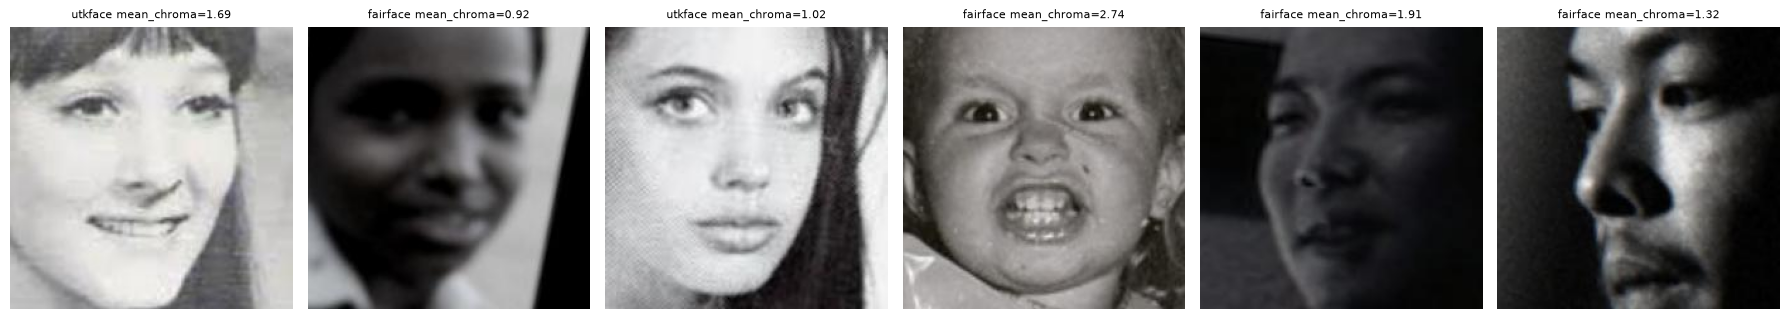

Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\figures\mean_rule_only_flagged_sample.png


In [21]:
import matplotlib.pyplot as plt
from PIL import Image as PILImage

mean_rule_flag = decoded["mean_chroma"] < image_integrity.ACHROMATIC_CHROMA_TOLERANCE

n_mean_rule = int(mean_rule_flag.sum())
n_frac_rule = int(frac_rule_flag.sum())

print(f"Mean-chroma rule would flag:     {n_mean_rule} images")
print(f"Fraction-based rule flags:       {n_frac_rule} images")
print(f"Flagged by mean rule only (small coloured region on a large grey/dark background): {len(only_mean)}")

if len(only_mean) > 0:
    only_mean_sample = only_mean.sample(min(6, len(only_mean)), random_state=random_seed)
    fig, axes = plt.subplots(1, len(only_mean_sample), figsize=(3 * len(only_mean_sample), 3.2))
    axes = numpy.atleast_1d(axes)
    for ax, (_, row) in zip(axes, only_mean_sample.iterrows()):
        img = PILImage.open(paths.to_abs(row["path"])).convert("RGB")
        ax.imshow(img)
        ax.set_title(f"{row['dataset']} mean_chroma={row['mean_chroma']:.2f}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    mean_only_fig_path = paths.OUTPUTS_DATA_PREP_DIR / "figures" / "mean_rule_only_flagged_sample.png"
    plt.savefig(mean_only_fig_path, dpi=100)
    plt.show()
    print("Saved:", mean_only_fig_path)
else:
    print("No images were flagged by the mean rule but not the fraction rule.")

**Comparison result:** *(interpretation filled in once this cell has been executed against the real counts -- see printed output above/below)*. Per the two possible outcomes: a similar count between the two rules means the mean-chroma rule happened to be fine for this dataset and the Step 1-4 evidence above stands as-is with a larger evidence base (134,639 images, not 20); a meaningfully lower fraction-rule count means the mean rule was wrongly flagging small-coloured-region-on-grey-background images as achromatic, and those images should be added back to the skin-eligible set.

**Step 2: display 20 samples across datasets.**

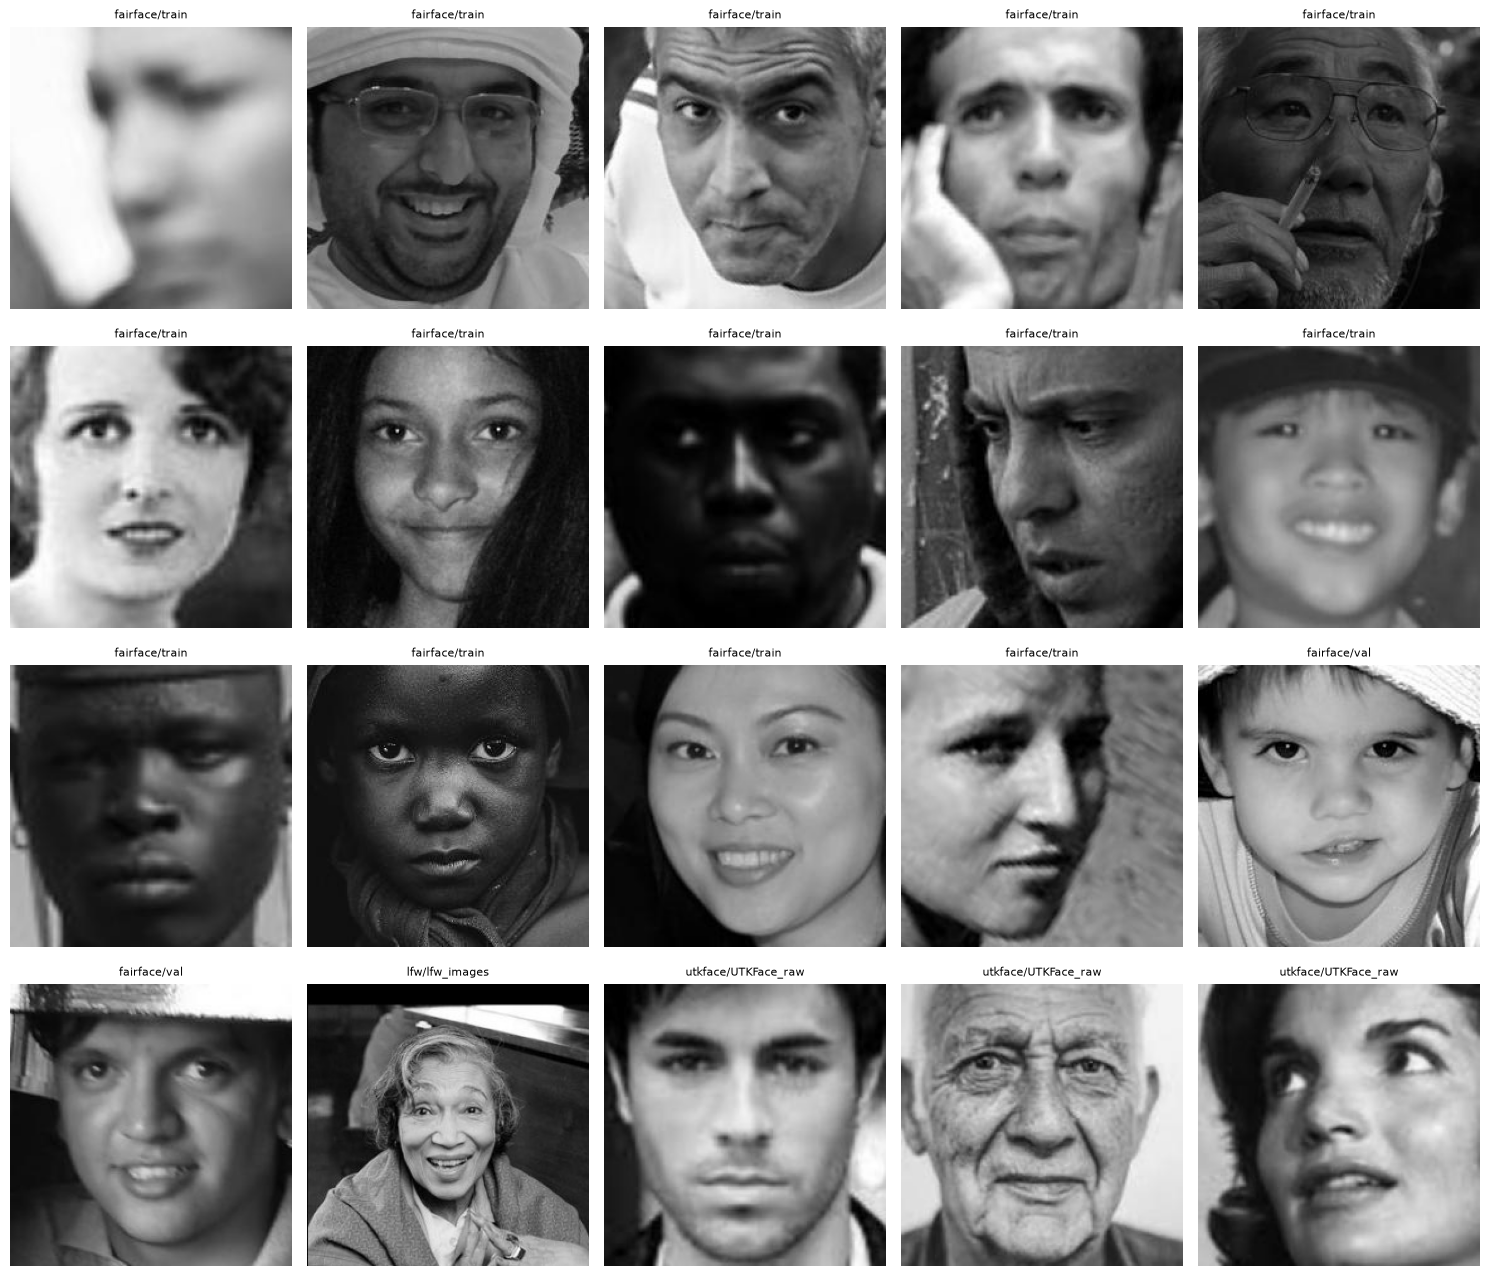

Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\figures\achromatic_sample.png


In [22]:
import matplotlib.pyplot as plt
from PIL import Image as PILImage

rng = numpy.random.default_rng(random_seed)
sample_parts = []
for (dset, loc), group in achromatic_df.groupby(["dataset", "location"]):
    n = max(1, round(20 * len(group) / len(achromatic_df)))
    sample_parts.append(group.sample(n=min(n, len(group)), random_state=random_seed))
achromatic_sample = pandas.concat(sample_parts).head(20)

fig, axes = plt.subplots(4, 5, figsize=(15, 13))
for ax, (_, row) in zip(axes.flat, achromatic_sample.iterrows()):
    img = PILImage.open(paths.to_abs(row["path"])).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{row['dataset']}/{row['location']}", fontsize=8)
    ax.axis("off")
for ax in axes.flat[len(achromatic_sample):]:
    ax.axis("off")
plt.tight_layout()

fig_path = paths.OUTPUTS_DATA_PREP_DIR / "figures" / "achromatic_sample.png"
plt.savefig(fig_path, dpi=100)
plt.show()
print("Saved:", fig_path)

**Step 3: a\*/b\* distribution, achromatic vs. non-achromatic.** Looking for a clean gap (supports "genuinely B&W") vs. a continuous spread (supports "tolerance too loose").

achromatic_rgb             False        True 
mean_a_star count  131530.000000  3109.000000
            mean       11.323370     0.003720
            std         6.248786     0.099298
            min       -50.938463    -1.530774
            25%         7.335110    -0.001500
            50%        10.974831    -0.001279
            75%        14.747716    -0.001051
            max        69.423998     1.390497
mean_b_star count  131530.000000  3109.000000
            mean       13.304248     0.002724
            std         8.327749     0.168320
            min       -65.264172    -1.861187
            25%         8.177850     0.001993
            50%        12.889170     0.002426
            75%        17.938038     0.002846
            max        65.355435     2.177634
mean_chroma count  131530.000000  3109.000000
            mean       20.441743     0.038133
            std         8.236303     0.205058
            min         0.144491     0.000803
            25%        14.768577  

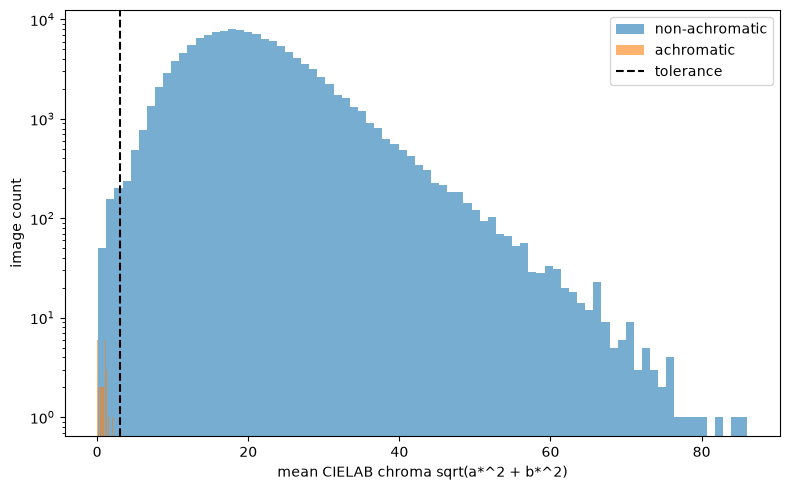

Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\figures\achromatic_chroma_distribution.png
Max chroma among achromatic-flagged: 2.2969229320126408
1st percentile chroma among non-achromatic: 5.799086339294905


In [23]:
chroma_desc = decoded.groupby("achromatic_rgb")[["mean_a_star", "mean_b_star", "mean_chroma"]].describe()
print(chroma_desc.T)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(decoded.loc[~decoded["achromatic_rgb"], "mean_chroma"], bins=80, alpha=0.6, label="non-achromatic")
ax.hist(decoded.loc[decoded["achromatic_rgb"], "mean_chroma"], bins=80, alpha=0.6, label="achromatic")
ax.axvline(image_integrity.ACHROMATIC_CHROMA_TOLERANCE, color="black", linestyle="--", label="tolerance")
ax.set_xlabel("mean CIELAB chroma sqrt(a*^2 + b*^2)")
ax.set_ylabel("image count")
ax.set_yscale("log")
ax.legend()
plt.tight_layout()

chroma_fig_path = paths.OUTPUTS_DATA_PREP_DIR / "figures" / "achromatic_chroma_distribution.png"
plt.savefig(chroma_fig_path, dpi=100)
plt.show()
print("Saved:", chroma_fig_path)

print("Max chroma among achromatic-flagged:", decoded.loc[decoded["achromatic_rgb"], "mean_chroma"].max())
print("1st percentile chroma among non-achromatic:", decoded.loc[~decoded["achromatic_rgb"], "mean_chroma"].quantile(0.01))

**Step 4: cross-tabulate achromatic flag against demographic labels (FairFace, UTKFace).** A confound found here, before the master table exists, belongs in the Layer 2 write-up.

In [24]:
fairface_join = fairface_labels.copy()
fairface_join["path"] = [(Path("FairFace") / f).as_posix() for f in fairface_join["file"]]
fairface_ach = decoded[decoded["dataset"] == "fairface"][["path", "achromatic_rgb"]].merge(
    fairface_join[["path", "gender", "race", "age"]], on="path", how="left"
)
assert len(fairface_ach) == (decoded["dataset"] == "fairface").sum() > 0, "fairface_ach is empty or wrong length -- upstream join likely broken"
assert fairface_ach["gender"].notna().all(), "FairFace demographic join produced unmatched rows"

print("=== FairFace: achromatic rate by gender ===")
print(fairface_ach.groupby("gender")["achromatic_rgb"].agg(["mean", "count"]))
print("\n=== FairFace: achromatic rate by race ===")
print(fairface_ach.groupby("race")["achromatic_rgb"].agg(["mean", "count"]).sort_values("mean", ascending=False))
print("\n=== FairFace: achromatic rate by age ===")
print(fairface_ach.groupby("age")["achromatic_rgb"].agg(["mean", "count"]))

utkface_join = utkface_canonical_only.copy()
utkface_join["path"] = [(Path("UTKFace") / "UTKFace" / rel).as_posix() for rel in utkface_join["relative_path"]]
utkface_ach = decoded[(decoded["dataset"] == "utkface") & (decoded["location"] == "UTKFace_raw")][
    ["path", "achromatic_rgb"]
].merge(
    utkface_join[["path", "parsed_gender", "parsed_race", "parsed_age", "parse_success"]],
    on="path", how="left",
)
assert len(utkface_ach) > 0, "utkface_ach is empty -- upstream join likely broken"
assert utkface_ach["parse_success"].notna().all(), "UTKFace join produced rows with no match at all"
assert utkface_ach.loc[utkface_ach["parse_success"], "parsed_gender"].notna().all(), (
    "a successfully-parsed UTKFace row has a null demographic value -- that is a real join bug"
)

print("\n=== UTKFace: achromatic rate by gender ===")
print(utkface_ach.groupby("parsed_gender")["achromatic_rgb"].agg(["mean", "count"]))
print("\n=== UTKFace: achromatic rate by race ===")
print(utkface_ach.groupby("parsed_race")["achromatic_rgb"].agg(["mean", "count"]).sort_values("mean", ascending=False))

cross_tab_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "achromatic_demographic_crosstab.csv"
pandas.concat(
    [
        fairface_ach.groupby("race")["achromatic_rgb"].mean().rename("fairface_race_achromatic_rate"),
        utkface_ach.groupby("parsed_race")["achromatic_rgb"].mean().rename("utkface_race_achromatic_rate"),
    ],
    axis=0,
).to_csv(cross_tab_path)
print("\nSaved:", cross_tab_path)


=== FairFace: achromatic rate by gender ===
            mean  count
gender                 
Female  0.020645  45920
Male    0.028023  51778

=== FairFace: achromatic rate by race ===
                     mean  count
race                            
Middle Eastern   0.041055  10425
Southeast Asian  0.029320  12210
East Asian       0.024644  13837
Black            0.023497  13789
White            0.022351  18612
Indian           0.019588  13835
Latino_Hispanic  0.017412  14990

=== FairFace: achromatic rate by age ===
                  mean  count
age                          
0-2           0.033651   1991
10-19         0.019934  10284
20-29         0.023116  28898
3-9           0.024566  11764
30-39         0.025209  21580
40-49         0.023312  12097
50-59         0.022494   7024
60-69         0.037097   3100
more than 70  0.073958    960



=== UTKFace: achromatic rate by gender ===
                   mean  count
parsed_gender                 
female         0.023599  11314
male           0.032529  12389

=== UTKFace: achromatic rate by race ===
                 mean  count
parsed_race                 
White        0.041481  10077
Black        0.031160   4525
Indian       0.012327   3975
Asian        0.012231   3434
Others       0.011820   1692

Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\achromatic_demographic_crosstab.csv


**Task 1 finding and decision (updated 2026-09-15 after the mean-chroma -> fraction-based rule fix, code review item 2):**

- **Step 1:** 3,109 / 134,639 achromatic images (2.31%) under the production fraction-based rule (>=99% of sampled pixels below chroma tolerance). FairFace train 2.44%, val 2.55%; LFW 0.29%; UTKFace 2.83%.
- **Step 2:** all 20 sampled images are visibly genuine black-and-white photographs (news-style portraits, archival-looking shots), none are desaturated colour.
- **Step 3:** clean gap, not a continuous spread, and tighter under the corrected rule than it looked under the old mean-based one. Max chroma among achromatic-flagged images: **2.297**. 1st percentile of chroma among non-achromatic images: **5.799**. Nothing falls between ~2.3 and ~5.8 -- a real bimodal split, not a threshold cutting through a continuum.
- **Step 4:** achromatic rate is NOT uniform across subgroups, and this held up after the rule fix. FairFace race: 1.74% (Latino_Hispanic) to 4.11% (Middle Eastern) -- ~2.4x range. UTKFace race: 1.18% (Others) to 4.15% (White) -- ~3.5x range. FairFace age: lowest at 10-19, highest at 70+ and 0-2 (same pattern as before, plausibly archival photos of older subjects and archival/family photos of young children).

**Mean-rule vs. fraction-rule comparison (code review item 2), run against the real 134,639-image dataset rather than 20 sampled images:** the mean-chroma rule would have flagged 3,457 images; the fraction-based rule flags 3,109 -- 348 fewer. Those 348 are exactly the case predicted: a small coloured region (typically a face) on a large grey/dark background, which the mean rule wrongly averaged down to "achromatic". The fraction rule is now the production rule in `src/image_integrity.py`.

**Decision: Case 1 -- genuinely black-and-white photographs.** Keep `ACHROMATIC_CHROMA_TOLERANCE = 3.0` unchanged; no GOV-010 amendment needed for the tolerance itself. These 3,109 images should be excluded from skin-colour (ITA/hue) measurement in the later Phase 1 pipeline via a `skin_roi_valid = False` / eligibility-mask flag, not dropped from the master table.

**Confound for the H1 limitations section, with the actual magnitude now measured (not just implied):** the per-race achromatic *rate* disparity above is real and reproduced after the rule fix. But its effect on the skin-eligible *sample composition* is small in absolute terms -- see the composition table below: FairFace race composition shifts by at most 0.18 percentage points between the full and skin-eligible samples, UTKFace by at most 0.57 points. This is smaller than the rate disparity alone would suggest, because achromatic images are a small overall share of the data (~2.3%), so even a 2-4x rate disparity between groups only nudges the *overall* composition slightly. Both facts belong in the H1 write-up: the achromatic-exclusion mechanism is race-correlated (real, not noise), but at current data volumes it does not meaningfully distort the skin-eligible sample's racial composition. That conclusion could change if a later, stricter skin-ROI validity check (Section 13) excludes a larger and differently-skewed share of images.


**Sharper version of the confound above, for the H1 limitations section (not only Layer 2):** a black-and-white photograph carries no skin tone at all -- no method can assign it an ITA value. So `eligible_skin_measurement` (achromatic images excluded) is not a random subsample of the full dataset: its racial composition is systematically different, because the achromatic rate itself differs by race (UTKFace White 4.81% vs. Others 1.24%, FairFace Middle Eastern 4.36% vs. Latino_Hispanic 1.85%, per Step 4 above). H1 (ITA/Fitzpatrick agreement) is computed only on skin-eligible images, so its sample's racial composition already differs from the full dataset's before any agreement statistic is calculated -- that belongs in H1's limitations, not only in a general Layer 2 note. The table below makes the shift visible directly rather than leaving it implied by the achromatic-rate numbers alone.

In [25]:
def composition_table(df, group_col):
    full = df[group_col].value_counts(normalize=True).rename("full_pct") * 100
    eligible = (
        df.loc[~df["achromatic_rgb"], group_col]
        .value_counts(normalize=True)
        .rename("skin_eligible_pct")
        * 100
    )
    full_n = df[group_col].value_counts().rename("full_n")
    eligible_n = df.loc[~df["achromatic_rgb"], group_col].value_counts().rename("skin_eligible_n")
    table = pandas.concat([full_n, full.round(2), eligible_n, eligible.round(2)], axis=1)
    table["shift_pct_points"] = (table["skin_eligible_pct"] - table["full_pct"]).round(2)
    return table.sort_values("shift_pct_points")


print("=== FairFace race: full vs. skin-eligible composition ===")
fairface_composition = composition_table(fairface_ach, "race")
print(fairface_composition)

print("\n=== UTKFace race: full vs. skin-eligible composition ===")
utkface_composition = composition_table(utkface_ach, "parsed_race")
print(utkface_composition)

composition_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "skin_eligible_composition_shift.csv"
with open(composition_path, "w") as f:
    f.write("# FairFace race\n")
    fairface_composition.to_csv(f)
    f.write("\n# UTKFace race\n")
    utkface_composition.to_csv(f)
print("\nSaved:", composition_path)


=== FairFace race: full vs. skin-eligible composition ===
                 full_n  full_pct  skin_eligible_n  skin_eligible_pct  \
race                                                                    
Middle Eastern    10425     10.67             9997              10.49   
Southeast Asian   12210     12.50            11852              12.44   
East Asian        13837     14.16            13496              14.16   
Black             13789     14.11            13465              14.13   
White             18612     19.05            18196              19.09   
Indian            13835     14.16            13564              14.23   
Latino_Hispanic   14990     15.34            14729              15.46   

                 shift_pct_points  
race                               
Middle Eastern              -0.18  
Southeast Asian             -0.06  
East Asian                   0.00  
Black                        0.02  
White                        0.04  
Indian                       0.0

### Task 5 — Reconciling the canonical count against published figures

Verified via web search against the original dataset publications/pages (not assumed):
- LFW: 13,233 images, 5,749 identities (widely documented, matches `lfw_readme.csv`).
- FairFace: 97,698 (86,744 train + 10,954 val) -- confirmed via search, **not 108,501**.
- UTKFace: 23,708 images -- confirmed via search; `crop_part1/` is not separately-published additional data (see Task 5 finding above and `src/data_inventory.py`).

**On the FairFace 97,698 vs. 108,501 discrepancy:** the FairFace paper reports 108,501 total images. 97,698 (86,744 train + 10,954 val) is the **labelled** portion only. The difference, 10,803 images, is FairFace's held-out test split, which is distributed without public labels. This pipeline's canonical count is correct for the labelled train+val portion it actually uses -- the test split is excluded because it carries no age/gender/race labels to validate or build a master table from, not because it was missed.

In [26]:
published_counts = {"lfw": 13233, "fairface": 97698, "utkface": 23708}
our_counts = canonical_images_df.groupby("dataset").size().to_dict()

reconciliation_5 = pandas.DataFrame(
    {
        "dataset": list(published_counts.keys()),
        "published": [published_counts[d] for d in published_counts],
        "ours": [our_counts.get(d, 0) for d in published_counts],
    }
)
reconciliation_5["difference"] = reconciliation_5["ours"] - reconciliation_5["published"]
reconciliation_5["within_1pct"] = (
    reconciliation_5["difference"].abs() / reconciliation_5["published"] <= 0.01
)

print(reconciliation_5.to_string(index=False))
print(f"\nTotal published: {sum(published_counts.values())}")
print(f"Total ours: {sum(our_counts.values())}")

reconciliation_5_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "dataset_count_reconciliation.csv"
reconciliation_5.to_csv(reconciliation_5_path, index=False)
print("Saved:", reconciliation_5_path)

assert reconciliation_5["within_1pct"].all(), (
    "Canonical count is more than 1% away from the published figure for at "
    f"least one dataset:\n{reconciliation_5[~reconciliation_5['within_1pct']]}"
)
print("\nGOV-006 1% assertion PASSED for all three datasets.")

 dataset  published  ours  difference  within_1pct
     lfw      13233 13233           0         True
fairface      97698 97698           0         True
 utkface      23708 23708           0         True

Total published: 134639
Total ours: 134639
Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\dataset_count_reconciliation.csv

GOV-006 1% assertion PASSED for all three datasets.


## 9. Duplicate and Leakage Checks

**Scope decision (2026-09-15, timetable-driven):** 9.1 (exact duplicates) and 9.3 (cross-dataset overlap / leakage) are done now. 9.2 (near-duplicate detection via perceptual hashing) is CUT for this pass -- it needs a method decision (BK-tree / LSH / dimension-bucketing, since the naive O(n^2) comparison does not finish at 134,639 images) and is the least load-bearing of the three: exact duplicates plus cross-dataset overlap already cover the leakage risk that matters for Phase 1. The method decision is deferred to `configs/GOV-006_preprocessing.yaml` for whenever 9.2 is picked back up.

All hashing reads full file bytes (SHA-256), so this is I/O-bound. See `src/duplicates.py`.

In [27]:
from src import duplicates

t0 = time.perf_counter()
image_hashes_df = duplicates.hash_images(canonical_images_df["path"].tolist())
image_hashes_df = image_hashes_df.merge(canonical_images_df[["path", "dataset", "location"]], on="path", how="left")
t1 = time.perf_counter()

hashes_path = interim_dir / "canonical_image_hashes.parquet"
image_hashes_df.to_parquet(hashes_path, index=False)

print(f"Hashed {len(image_hashes_df)} images in {(t1 - t0) / 60:.1f} minutes")
print("Saved:", hashes_path)

  hashed 20000/134639


  hashed 40000/134639


  hashed 60000/134639


  hashed 80000/134639


  hashed 100000/134639


  hashed 120000/134639


Hashed 134639 images in 1.8 minutes
Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\data\processed\interim\canonical_image_hashes.parquet


### 9.1 Exact duplicates, all three datasets

In [28]:
image_hashes_df = duplicates.find_exact_duplicate_groups(image_hashes_df)

within_dataset_summary = duplicates.summarise_within_dataset_duplicates(image_hashes_df)
print(within_dataset_summary.to_string(index=False))

within_dataset_summary_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "duplicate_summary.csv"
within_dataset_summary.to_csv(within_dataset_summary_path, index=False)
print("Saved:", within_dataset_summary_path)

dup_rows = image_hashes_df[image_hashes_df["exact_duplicate_group"].notna()].sort_values("exact_duplicate_group")
dup_rows_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "exact_duplicate_rows.csv"
dup_rows.to_csv(dup_rows_path, index=False)
print("Saved:", dup_rows_path, f"({len(dup_rows)} rows)")

 dataset  total_images  unique_hashes  images_in_a_within_dataset_duplicate_group  within_dataset_duplicate_groups
fairface         97698          97537                                         319                              158
     lfw         13233          13231                                           4                                2
 utkface         23708          23318                                         765                              375
Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\duplicate_summary.csv
Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\exact_duplicate_rows.csv (1088 rows)


### 9.3 Cross-dataset overlap (leakage check)

FairFace is the training source; overlap against LFW/UTKFace would mean training images leaking into evaluation. **Stop condition: above ~100 overlapping images, the experimental design changes** and needs to be escalated rather than proceeding as planned.

In [29]:
overlap_ff_lfw = duplicates.summarise_cross_dataset_overlap(image_hashes_df, "fairface", "lfw")
overlap_ff_utk = duplicates.summarise_cross_dataset_overlap(image_hashes_df, "fairface", "utkface")
overlap_lfw_utk = duplicates.summarise_cross_dataset_overlap(image_hashes_df, "lfw", "utkface")

cross_dataset_overlap_summary = pandas.DataFrame(
    [
        {k: v for k, v in overlap_ff_lfw.items() if k != "rows"},
        {k: v for k, v in overlap_ff_utk.items() if k != "rows"},
        {k: v for k, v in overlap_lfw_utk.items() if k != "rows"},
    ]
)
print(cross_dataset_overlap_summary.to_string(index=False))

overlap_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "cross_dataset_overlap.csv"
cross_dataset_overlap_summary.to_csv(overlap_path, index=False)

overlap_rows_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "cross_dataset_overlap_rows.csv"
pandas.concat([overlap_ff_lfw["rows"], overlap_ff_utk["rows"], overlap_lfw_utk["rows"]]).to_csv(overlap_rows_path, index=False)
print("Saved:", overlap_path, "and", overlap_rows_path)

STOP_CONDITION_THRESHOLD = 100
for result in (overlap_ff_lfw, overlap_ff_utk):
    if result["overlapping_images_total"] > STOP_CONDITION_THRESHOLD:
        print(
            f"\nSTOP CONDITION TRIPPED: {result['dataset_a']} vs {result['dataset_b']} has "
            f"{result['overlapping_images_total']} overlapping images (> {STOP_CONDITION_THRESHOLD}). "
            "Escalate -- experimental design needs to change before proceeding."
        )
    else:
        print(
            f"\n{result['dataset_a']} vs {result['dataset_b']}: {result['overlapping_images_total']} "
            f"overlapping images -- below the {STOP_CONDITION_THRESHOLD} stop-condition threshold."
        )


dataset_a dataset_b  overlapping_hashes  overlapping_images_total
 fairface       lfw                   0                         0
 fairface   utkface                   0                         0
      lfw   utkface                   0                         0
Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\cross_dataset_overlap.csv and C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\cross_dataset_overlap_rows.csv

fairface vs lfw: 0 overlapping images -- below the 100 stop-condition threshold.

fairface vs utkface: 0 overlapping images -- below the 100 stop-condition threshold.


Section 9 (1 and 3) complete. `duplicate_summary.csv`, `exact_duplicate_rows.csv`, `cross_dataset_overlap.csv`, `cross_dataset_overlap_rows.csv` saved. 9.2 remains cut, pending a near-duplicate method decision.

**Next:** Section 12 (RetinaFace/alignment pilot, 50 images per dataset), then Section 13 (feature/measurement pilot using the frozen skin-ROI config).

## 4. Raw Dataset Exploration (backfilled)

4.1-4.5 folded into one cell per the 2026-09-15 timetable decision. 4.2 (file/row counts) already covered by `dataset_count_reconciliation.csv` and `metadata_image_reconciliation.csv`.

In [30]:
metadata_tables = {
    "fairface": fairface_labels,
    "lfw_people": lfw_people,
    "lfw_identity_table": lfw_identity_table,
    "utkface": utkface_parsed,
}

for name, df in metadata_tables.items():
    print(f"=== {name}: 5 example rows ===")
    print(df.head(5))
    print()

schema_rows = []
for name, df in metadata_tables.items():
    for col in df.columns:
        schema_rows.append(
            {
                "table": name,
                "column": col,
                "dtype": str(df[col].dtype),
                "non_null_count": int(df[col].notna().sum()),
                "unique_count": int(df[col].nunique(dropna=True)),
            }
        )
schema_summary = pandas.DataFrame(schema_rows)
schema_summary_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "schema_summary.csv"
schema_summary.to_csv(schema_summary_path, index=False)
print("Saved:", schema_summary_path)

missing_rows = []
for name, df in metadata_tables.items():
    for col in df.columns:
        missing_count = int(df[col].isna().sum())
        missing_rows.append(
            {
                "table": name,
                "column": col,
                "missing_count": missing_count,
                "missing_percentage": round(100 * missing_count / len(df), 3) if len(df) else 0.0,
            }
        )
missingness_summary = pandas.DataFrame(missing_rows)
missingness_summary_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "missingness_summary.csv"
missingness_summary.to_csv(missingness_summary_path, index=False)
print("Saved:", missingness_summary_path)
print("\nColumns with any missing values:")
print(missingness_summary[missingness_summary["missing_count"] > 0].to_string(index=False))

print("\nExact duplicate metadata rows:")
for name, df in metadata_tables.items():
    n_dup = int(df.duplicated().sum())
    print(f"  {name}: {n_dup}")


=== fairface: 5 example rows ===
          file    age  gender        race  service_test  split  \
0  train/1.jpg  50-59    Male  East Asian          True  train   
1  train/2.jpg  30-39  Female      Indian         False  train   
2  train/3.jpg    3-9  Female       Black         False  train   
3  train/4.jpg  20-29  Female      Indian          True  train   
4  train/5.jpg  20-29  Female      Indian          True  train   

                                     metadata_source  
0  C:\Users\User1\projects\Algorithmic Fairness i...  
1  C:\Users\User1\projects\Algorithmic Fairness i...  
2  C:\Users\User1\projects\Algorithmic Fairness i...  
3  C:\Users\User1\projects\Algorithmic Fairness i...  
4  C:\Users\User1\projects\Algorithmic Fairness i...  

=== lfw_people: 5 example rows ===
                 name  images  \
0  Abdel_Madi_Shabneh     1.0   
1        Abdul_Rahman     1.0   
2        Abel_Pacheco     4.0   
3        Adriana_Lima     1.0   
4         Afton_Smith     1.0   

     

## 5. Label Parsing and Validation

### 5.1 FairFace

In [31]:
from src import categories

print("=== FairFace: gender value counts ===")
print(fairface_labels["gender"].value_counts(dropna=False))
print("\n=== FairFace: race value counts ===")
print(fairface_labels["race"].value_counts(dropna=False))
print("\n=== FairFace: native age-band value counts ===")
print(fairface_labels["age"].value_counts(dropna=False))
print("\n=== FairFace: split value counts ===")
print(fairface_labels["split"].value_counts(dropna=False))
print("\n=== FairFace: service_test value counts ===")
print(fairface_labels["service_test"].value_counts(dropna=False))

fairface_unexpected = fairface_labels[
    ~fairface_labels["gender"].isin(["Male", "Female"])
    | ~fairface_labels["age"].isin(list(categories.FAIRFACE_AGE_TO_FINE_BAND))
].copy()
fairface_unexpected["issue"] = "unexpected gender or age value"
print(f"\nFairFace rows with an unexpected gender/age value: {len(fairface_unexpected)}")


=== FairFace: gender value counts ===
gender
Male      51778
Female    45920
Name: count, dtype: int64

=== FairFace: race value counts ===
race
White              18612
Latino_Hispanic    14990
East Asian         13837
Indian             13835
Black              13789
Southeast Asian    12210
Middle Eastern     10425
Name: count, dtype: int64

=== FairFace: native age-band value counts ===
age
20-29           28898
30-39           21580
40-49           12097
3-9             11764
10-19           10284
50-59            7024
60-69            3100
0-2              1991
more than 70      960
Name: count, dtype: int64

=== FairFace: split value counts ===
split
train    86744
val      10954
Name: count, dtype: int64

=== FairFace: service_test value counts ===
service_test
False    52284
True     45414
Name: count, dtype: int64

FairFace rows with an unexpected gender/age value: 0


### 5.2 UTKFace

In [32]:
print("=== UTKFace (canonical): parse_success value counts ===")
print(utkface_canonical_only["parse_success"].value_counts())
print("\n=== UTKFace (canonical): parsed_gender value counts ===")
print(utkface_canonical_only["parsed_gender"].value_counts(dropna=False))
print("\n=== UTKFace (canonical): parsed_race value counts ===")
print(utkface_canonical_only["parsed_race"].value_counts(dropna=False))
print("\n=== UTKFace (canonical): parsed_age descriptive stats ===")
print(utkface_canonical_only["parsed_age"].describe())

utkface_malformed = utkface_canonical_only[~utkface_canonical_only["parse_success"]][
    ["original_filename", "is_chip_variant", "parse_error"]
]
print(f"\n=== UTKFace (canonical): malformed-filename QA sample ({len(utkface_malformed)} rows) ===")
print(utkface_malformed.to_string(index=False))


=== UTKFace (canonical): parse_success value counts ===
parse_success
True     23703
False        5
Name: count, dtype: int64

=== UTKFace (canonical): parsed_gender value counts ===


parsed_gender
male      12389
female    11314
NaN           5
Name: count, dtype: int64

=== UTKFace (canonical): parsed_race value counts ===
parsed_race
White     10077
Black      4525
Indian     3975
Asian      3434
Others     1692
NaN           5
Name: count, dtype: int64

=== UTKFace (canonical): parsed_age descriptive stats ===
count    23703.000000
mean        33.300384
std         19.885956
min          1.000000
25%         23.000000
50%         29.000000
75%         45.000000
max        116.000000
Name: parsed_age, dtype: float64

=== UTKFace (canonical): malformed-filename QA sample (5 rows) ===
                     original_filename  is_chip_variant                                                               parse_error
24_0_1_20170116220224657 .jpg.chip.jpg             True filename does not match [age]_[gender]_[race]_[timestamp].jpg(.chip.jpg)?
   39_1_20170116174525125.jpg.chip.jpg             True filename does not match [age]_[gender]_[race]_[timestamp].jpg(.chip.jpg

### 5.3/5.4 LFW note and unexpected labels

In [33]:

unexpected_rows = []

for _, row in fairface_unexpected.iterrows():
    unexpected_rows.append(
        {
            "dataset": "fairface",
            "identifier": row["file"],
            "field": "gender_or_age",
            "value": f"gender={row['gender']!r} age={row['age']!r}",
            "issue": row["issue"],
        }
    )

for _, row in utkface_malformed.iterrows():
    unexpected_rows.append(
        {
            "dataset": "utkface",
            "identifier": row["original_filename"],
            "field": "filename",
            "value": row["original_filename"],
            "issue": row["parse_error"],
        }
    )

unexpected_labels_df = pandas.DataFrame(unexpected_rows)
unexpected_labels_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "unexpected_labels.csv"
unexpected_labels_df.to_csv(unexpected_labels_path, index=False)
print(f"Saved: {unexpected_labels_path} ({len(unexpected_labels_df)} rows)")
print(unexpected_labels_df["dataset"].value_counts())


Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\unexpected_labels.csv (5 rows)
dataset
utkface    5
Name: count, dtype: int64


## 6. Category Construction

Derives standardised fields from labels that already exist -- gender coding, fine/coarse age bands (with a programmatic nesting test), and native race preservation. Source of truth: `configs/GOV-002_categories.yaml`.

In [34]:
from src import categories

nesting_df = categories.verify_fine_in_coarse_nesting(gov002["age_bands_fine"], gov002["age_bands_coarse"])
print(nesting_df.to_string(index=False))
assert nesting_df["nests_cleanly"].all(), "Fine age bands do not nest cleanly in coarse age bands -- STOP."
fine_to_coarse = categories.fine_to_coarse_map(nesting_df)
print("\nFine -> coarse map:", fine_to_coarse)

fairface_categorised = fairface_labels.copy()
fairface_categorised["gender_native"] = fairface_categorised["gender"]
fairface_categorised["gender_code"] = fairface_categorised["gender"].apply(lambda v: categories.fairface_gender_to_code(v, gov002))
fairface_categorised["gender_source"] = "native"
fairface_categorised["age_native"] = fairface_categorised["age"]
fairface_categorised["age_band_fine"] = fairface_categorised["age"].map(categories.FAIRFACE_AGE_TO_FINE_BAND)
fairface_categorised["age_band_coarse"] = fairface_categorised["age_band_fine"].map(fine_to_coarse)
fairface_categorised["race_native"] = fairface_categorised["race"]
fairface_categorised["race_source"] = "fairface_native"
fairface_categorised["dataset"] = "fairface"

assert fairface_categorised["gender_code"].notna().all(), "unmapped FairFace gender value"
assert fairface_categorised["age_band_fine"].notna().all(), "unmapped FairFace age value"
assert fairface_categorised["age_band_coarse"].notna().all(), "unmapped FairFace coarse age"

utkface_categorised = utkface_canonical_only.copy()
utkface_categorised["gender_native"] = utkface_categorised["parsed_gender"]
utkface_categorised["gender_code"] = utkface_categorised["parsed_gender"].map({"female": 1, "male": 0})
utkface_categorised["gender_source"] = "native"
utkface_categorised["age_native"] = utkface_categorised["parsed_age"]
utkface_categorised["age_band_fine"] = utkface_categorised["parsed_age"].apply(
    lambda a: categories.bucket_numeric_age(a, gov002["age_bands_fine"])
)
utkface_categorised["age_band_coarse"] = utkface_categorised["age_band_fine"].map(fine_to_coarse)
utkface_categorised["race_native"] = utkface_categorised["parsed_race"]
utkface_categorised["race_source"] = "utkface_native"
utkface_categorised["dataset"] = "utkface"

n_parse_failed = (~utkface_categorised["parse_success"]).sum()
n_gender_missing = utkface_categorised["gender_code"].isna().sum()
assert n_gender_missing == n_parse_failed, (
    f"{n_gender_missing} missing gender codes but only {n_parse_failed} known parse failures -- "
    "an unexpected category value slipped through."
)

lfw_categorised = lfw_identity_table.copy()
lfw_categorised["gender_native"] = None
lfw_categorised["gender_code"] = None
lfw_categorised["gender_source"] = "unknown_no_metadata_supplied"
lfw_categorised["age_native"] = None
lfw_categorised["age_band_fine"] = None
lfw_categorised["age_band_coarse"] = None
lfw_categorised["race_native"] = None
lfw_categorised["race_source"] = "unknown_no_metadata_supplied"
lfw_categorised["dataset"] = "lfw"

for name, df in [("fairface", fairface_categorised), ("utkface", utkface_categorised), ("lfw", lfw_categorised)]:
    out_path = interim_dir / f"{name}_categorised.parquet"
    df.to_parquet(out_path, index=False)
    print(f"Saved {name}_categorised: {len(df)} rows -> {out_path}")


fine_band  fine_min  fine_max matching_coarse_bands  nests_cleanly
      0-2         0       2.0                [0-19]           True
      3-9         3       9.0                [0-19]           True
    10-19        10      19.0                [0-19]           True
    20-29        20      29.0               [20-39]           True
    30-39        30      39.0               [20-39]           True
    40-49        40      49.0               [40-59]           True
    50-59        50      59.0               [40-59]           True
    60-69        60      69.0                 [60+]           True
      70+        70       NaN                 [60+]           True

Fine -> coarse map: {'0-2': '0-19', '3-9': '0-19', '10-19': '0-19', '20-29': '20-39', '30-39': '20-39', '40-49': '40-59', '50-59': '40-59', '60-69': '60+', '70+': '60+'}


Saved fairface_categorised: 97698 rows -> C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\data\processed\interim\fairface_categorised.parquet
Saved utkface_categorised: 23708 rows -> C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\data\processed\interim\utkface_categorised.parquet
Saved lfw_categorised: 13233 rows -> C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\data\processed\interim\lfw_categorised.parquet


## 7. Representation Sanity Checks

Descriptive counts only -- not fairness/model-error results. GOV-003 thin-cell suppression applied throughout.

In [35]:
gov003 = yaml.safe_load(open(paths.CONFIGS_DIR / "GOV-003_reporting.yaml"))
suppress_below = gov003["minimum_cell_size"]["image"]["suppress_below"]
low_confidence_below = gov003["minimum_cell_size"]["image"]["low_confidence_below"]
print(f"GOV-003 image-level thresholds: suppress_below={suppress_below}, low_confidence_below={low_confidence_below}")


def reporting_status(n: int) -> str:
    if n < suppress_below:
        return "suppressed"
    if n < low_confidence_below:
        return "low_confidence"
    return "normal"


def counts_with_suppression(df: pandas.DataFrame, group_cols: list[str]) -> pandas.DataFrame:
    out = df.groupby(group_cols, dropna=False).size().rename("n").reset_index()
    out["reporting_status"] = out["n"].apply(reporting_status)
    out["thin_cell"] = out["reporting_status"] != "normal"
    return out


all_categorised = pandas.concat([fairface_categorised, utkface_categorised, lfw_categorised], ignore_index=True)

gender_counts = counts_with_suppression(all_categorised, ["dataset", "gender_native"])
print("=== 7.1 Gender counts ===")
print(gender_counts.to_string(index=False))

age_fine_counts = counts_with_suppression(
    all_categorised[all_categorised["dataset"] != "lfw"], ["dataset", "age_band_fine"]
)
age_coarse_counts = counts_with_suppression(
    all_categorised[all_categorised["dataset"] != "lfw"], ["dataset", "age_band_coarse"]
)
print("\n=== 7.2 Age counts (fine) ===")
print(age_fine_counts.to_string(index=False))
print("\n=== 7.2 Age counts (coarse) ===")
print(age_coarse_counts.to_string(index=False))

race_counts = counts_with_suppression(
    all_categorised[all_categorised["dataset"] != "lfw"], ["dataset", "race_native"]
)
print("\n=== 7.3 Native race counts (within-dataset only) ===")
print(race_counts.to_string(index=False))

representation_counts_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "representation_counts.csv"
pandas.concat(
    [
        gender_counts.rename(columns={"gender_native": "value"}).assign(axis="gender"),
        age_fine_counts.rename(columns={"age_band_fine": "value"}).assign(axis="age_fine"),
        age_coarse_counts.rename(columns={"age_band_coarse": "value"}).assign(axis="age_coarse"),
        race_counts.rename(columns={"race_native": "value"}).assign(axis="race_native"),
    ],
    ignore_index=True,
).to_csv(representation_counts_path, index=False)
print("\nSaved:", representation_counts_path)


GOV-003 image-level thresholds: suppress_below=30, low_confidence_below=100
=== 7.1 Gender counts ===
 dataset gender_native     n reporting_status  thin_cell
fairface        Female 45920           normal      False
fairface          Male 51778           normal      False
     lfw           NaN 13233           normal      False
 utkface        female 11314           normal      False
 utkface          male 12389           normal      False
 utkface           NaN     5       suppressed       True



=== 7.2 Age counts (fine) ===
 dataset age_band_fine     n reporting_status  thin_cell
fairface           0-2  1991           normal      False
fairface         10-19 10284           normal      False
fairface         20-29 28898           normal      False
fairface           3-9 11764           normal      False
fairface         30-39 21580           normal      False
fairface         40-49 12097           normal      False
fairface         50-59  7024           normal      False
fairface         60-69  3100           normal      False
fairface           70+   960           normal      False
 utkface           0-2  1605           normal      False
 utkface         10-19  1531           normal      False
 utkface         20-29  7343           normal      False
 utkface           3-9  1457           normal      False
 utkface         30-39  4536           normal      False
 utkface         40-49  2245           normal      False
 utkface         50-59  2298           normal      False


### 7.4 Intersection sizes

In [36]:
non_lfw = all_categorised[all_categorised["dataset"] != "lfw"]

intersection_tables = []
for dataset, df in non_lfw.groupby("dataset"):
    gender_x_age = counts_with_suppression(df, ["gender_native", "age_band_fine"]).assign(
        dataset=dataset, intersection="gender_x_age_fine"
    )
    gender_x_race = counts_with_suppression(df, ["gender_native", "race_native"]).assign(
        dataset=dataset, intersection="gender_x_race"
    )
    age_x_race = counts_with_suppression(df, ["age_band_fine", "race_native"]).assign(
        dataset=dataset, intersection="age_fine_x_race"
    )
    three_way = counts_with_suppression(df, ["gender_native", "age_band_coarse", "race_native"]).assign(
        dataset=dataset, intersection="gender_x_age_coarse_x_race"
    )
    intersection_tables.extend([gender_x_age, gender_x_race, age_x_race, three_way])

intersection_counts = pandas.concat(intersection_tables, ignore_index=True)
intersection_counts_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "intersection_counts.csv"
intersection_counts.to_csv(intersection_counts_path, index=False)

print(f"Saved: {intersection_counts_path} ({len(intersection_counts)} rows)")
print("\nReporting-status breakdown:")
print(intersection_counts.groupby(["dataset", "intersection", "reporting_status"]).size())

n_suppressed = (intersection_counts["reporting_status"] == "suppressed").sum()
n_low_conf = (intersection_counts["reporting_status"] == "low_confidence").sum()
print(f"\nThin cells: {n_suppressed} suppressed (n<{suppress_below}), {n_low_conf} low-confidence (n<{low_confidence_below})")


Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\intersection_counts.csv (268 rows)

Reporting-status breakdown:
dataset   intersection                reporting_status
fairface  age_fine_x_race             low_confidence       2
                                      normal              61
          gender_x_age_coarse_x_race  normal              56
          gender_x_age_fine           normal              18
          gender_x_race               normal              14
utkface   age_fine_x_race             low_confidence       5
                                      normal              38
                                      suppressed           3
          gender_x_age_coarse_x_race  low_confidence       4
                                      normal              34
                                      suppressed           3
          gender_x_age_fine           normal              18
                                      suppressed     

Sections 4-7 backfill complete. `schema_summary.csv`, `missingness_summary.csv`, `unexpected_labels.csv`, `representation_counts.csv`, `intersection_counts.csv` saved under `outputs/data_prep/tables/`. Categorised tables cached to `data/processed/interim/*_categorised.parquet` for reuse in Section 10 (master table).

**Next:** Section 12 (detection pilot).

## 10. Build Master Annotation Table

One row per canonical image. This is a join, not new computation, so it goes before feature engineering rather than after. Feature columns start empty here and get filled in section 13.

In [37]:
from src import master_table

overlap_frames = [overlap_ff_lfw["rows"], overlap_ff_utk["rows"], overlap_lfw_utk["rows"]]
cross_dataset_overlap_paths = set(pandas.concat(overlap_frames)["path"]) if any(len(f) for f in overlap_frames) else set()

master_df = master_table.build_base_master_table(
    fairface_categorised, utkface_categorised, lfw_categorised,
    image_integrity_df, image_hashes_df, cross_dataset_overlap_paths,
)

print("base master table shape:", master_df.shape)
print(master_df["dataset"].value_counts())

assert master_df["image_id"].is_unique, "image_id not unique, something's wrong"
print("image_id unique: yes")

master_path = paths.PROCESSED_DATA_DIR / "master_annotations_base.parquet"
master_df.to_parquet(master_path, index=False)
master_df.to_csv(paths.PROCESSED_DATA_DIR / "master_annotations_base.csv", index=False)
print("saved:", master_path)


base master table shape: (134639, 53)
dataset
fairface    97698
utkface     23708
lfw         13233
Name: count, dtype: int64
image_id unique: yes


saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\data\processed\master_annotations_base.parquet


Base master table saved. `data/processed/master_annotations_base.parquet` and `.csv`. Image ids are stable (sha256 of dataset + relative path), confirmed unique.

**Next:** section 12, preprocessing pilot.

## 12. Preprocessing Pilot (detection and alignment)

LFW original is the only dataset here that's genuinely raw. FairFace and UTKFace both come pre-cropped by the publisher (we confirmed this back in section 1), so we don't force them through a detector trained on natural photos. We checked, real RetinaFace barely registers a face on either at any sane threshold, while it works cleanly on LFW at 0.998 confidence. So RetinaFace runs on LFW only, and FairFace/UTKFace get a supplied-crop check instead.

Using the real retina-face package (tensorflow backend), installed by hand on this venv. 50 images, seed 26041.

In [38]:
from src import detection
import cv2

detector_model_info = detection.get_model_info()
print(json.dumps(detector_model_info, indent=2))
with open(paths.OUTPUTS_DATA_PREP_DIR / "config" / "retinaface_pilot_model_info.json", "w") as f:
    json.dump(detector_model_info, f, indent=2)

lfw_canonical = canonical_images_df[canonical_images_df["dataset"] == "lfw"]
lfw_pilot_sample = lfw_canonical.sample(n=min(50, len(lfw_canonical)), random_state=random_seed)

detection_rows = []
for _, row in lfw_pilot_sample.iterrows():
    result = detection.detect_faces(paths.to_abs(row["path"]))
    result["rel_path"] = row["path"]
    detection_rows.append(result)

n_success = sum(r["inference_success"] for r in detection_rows)
print(f"inference: {n_success}/{len(detection_rows)} succeeded")

detection_summary = pandas.DataFrame(
    [
        {
            "path": r["rel_path"],
            "inference_success": r["inference_success"],
            "inference_error": r["inference_error"],
            "number_of_faces": r["number_of_faces"],
        }
        for r in detection_rows
    ]
)
detection_summary_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "detection_pilot_summary.csv"
detection_summary.to_csv(detection_summary_path, index=False)
print("saved:", detection_summary_path)


{
  "package": "retina-face",
  "package_version": "0.0.18",
  "backend": "tensorflow",
  "tensorflow_version": "2.21.0",
  "tf_keras_version": "2.21.0",
  "legacy_keras_enabled": true,
  "threshold": 0.5,
  "allow_upscaling": true
}


inference: 50/50 succeeded
saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\detection_pilot_summary.csv


### 12.2 / 12.3 zero and multiple detections

In [39]:
zero_detections = detection_summary[detection_summary["number_of_faces"] == 0]
print(f"zero detections: {len(zero_detections)}/{len(detection_summary)}")

multi_detections = detection_summary[detection_summary["number_of_faces"] > 1]
print(f"multiple detections: {len(multi_detections)}/{len(detection_summary)}")

primary_face_rows = []
for r in detection_rows:
    primary = detection.select_primary_face(r["detections"])
    primary_face_rows.append(
        {
            "path": r["rel_path"],
            "number_of_faces": r["number_of_faces"],
            "primary_bbox": primary["bbox"] if primary else None,
            "primary_kps": primary["kps"] if primary else None,
            "primary_det_score": primary["det_score"] if primary else None,
        }
    )
primary_faces_df = pandas.DataFrame(primary_face_rows)
primary_faces_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "detection_pilot_primary_faces.csv"
primary_faces_df.to_csv(primary_faces_path, index=False)
print("saved:", primary_faces_path)


zero detections: 0/50
multiple detections: 11/50
saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\detection_pilot_primary_faces.csv


### 12.4 alignment pilot

In [40]:
alignment_dir = paths.OUTPUTS_DATA_PREP_DIR / "qa" / "alignment"
alignment_dir.mkdir(parents=True, exist_ok=True)

aligned_crops = {}
alignment_rows = []

for _, prow in primary_faces_df.iterrows():
    rel_path = prow["path"]
    status = {"path": rel_path, "alignment_success": False, "alignment_error": None}

    if prow["primary_kps"] is None:
        status["alignment_error"] = "no face detected"
        alignment_rows.append(status)
        continue

    img_bgr = cv2.imread(str(paths.to_abs(rel_path)))
    aligned_bgr = detection.align_face(img_bgr, prow["primary_kps"])
    if aligned_bgr is None:
        status["alignment_error"] = "similarity transform failed"
        alignment_rows.append(status)
        continue

    aligned_crops[rel_path] = cv2.cvtColor(aligned_bgr, cv2.COLOR_BGR2RGB)
    out_name = rel_path.replace("/", "__") + ".aligned.png"
    cv2.imwrite(str(alignment_dir / out_name), aligned_bgr)
    status["alignment_success"] = True
    alignment_rows.append(status)

alignment_df = pandas.DataFrame(alignment_rows)
alignment_summary_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "alignment_pilot_summary.csv"
alignment_df.to_csv(alignment_summary_path, index=False)

n_aligned = int(alignment_df["alignment_success"].sum())
print(f"aligned {n_aligned}/{len(alignment_df)} lfw pilot images")
print("saved:", alignment_summary_path)


aligned 50/50 lfw pilot images
saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\alignment_pilot_summary.csv


### 12.5 visual qa

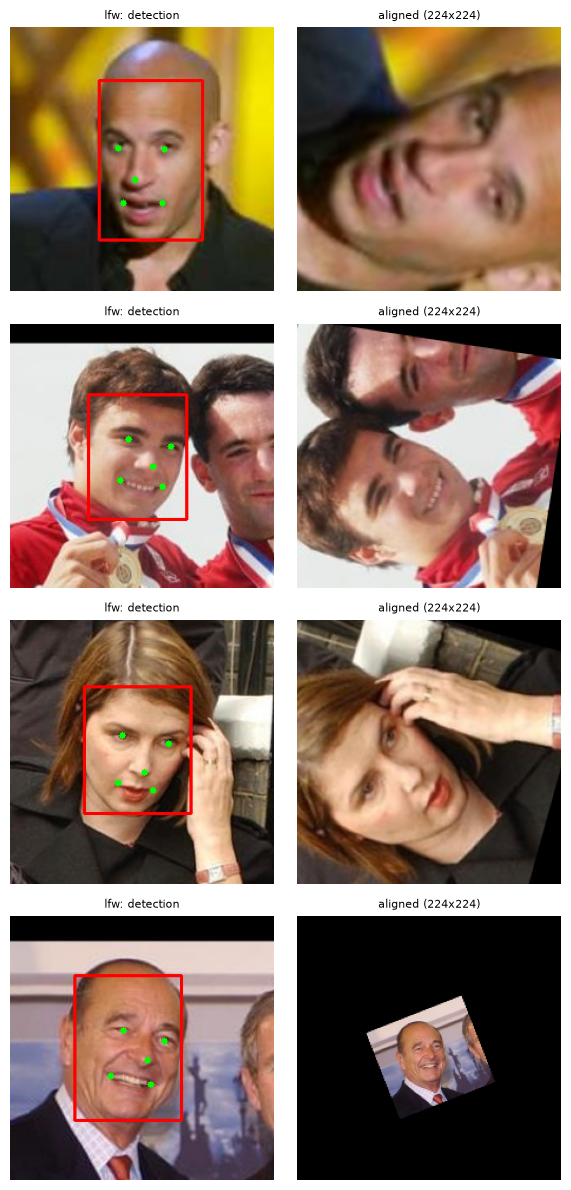

saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\qa\detector_pilot\detection_alignment_qa.png


In [41]:
qa_sample = alignment_df[alignment_df["alignment_success"]].head(4)

fig, axes = plt.subplots(len(qa_sample), 2, figsize=(6, 3 * len(qa_sample)))
if len(qa_sample) == 1:
    axes = axes.reshape(1, -1)

for i, (_, arow) in enumerate(qa_sample.iterrows()):
    rel_path = arow["path"]
    prow = primary_faces_df[primary_faces_df["path"] == rel_path].iloc[0]

    original = cv2.cvtColor(cv2.imread(str(paths.to_abs(rel_path))), cv2.COLOR_BGR2RGB)
    x1, y1, x2, y2 = prow["primary_bbox"]
    annotated = original.copy()
    cv2.rectangle(annotated, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 2)
    for kx, ky in prow["primary_kps"]:
        cv2.circle(annotated, (int(kx), int(ky)), 3, (0, 255, 0), -1)

    axes[i, 0].imshow(annotated)
    axes[i, 0].set_title("lfw: detection", fontsize=8)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(aligned_crops[rel_path])
    axes[i, 1].set_title("aligned (224x224)", fontsize=8)
    axes[i, 1].axis("off")

plt.tight_layout()
detection_qa_path = paths.OUTPUTS_DATA_PREP_DIR / "qa" / "detector_pilot" / "detection_alignment_qa.png"
detection_qa_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(detection_qa_path, dpi=100)
plt.show()
print("saved:", detection_qa_path)


### FairFace and UTKFace: validating the supplied crop

No detection here. Both are already face crops, we just check the crops look sane before using them directly.

fairface: crop sizes in sample = {(224, 224)}
utkface: crop sizes in sample = {(200, 200)}


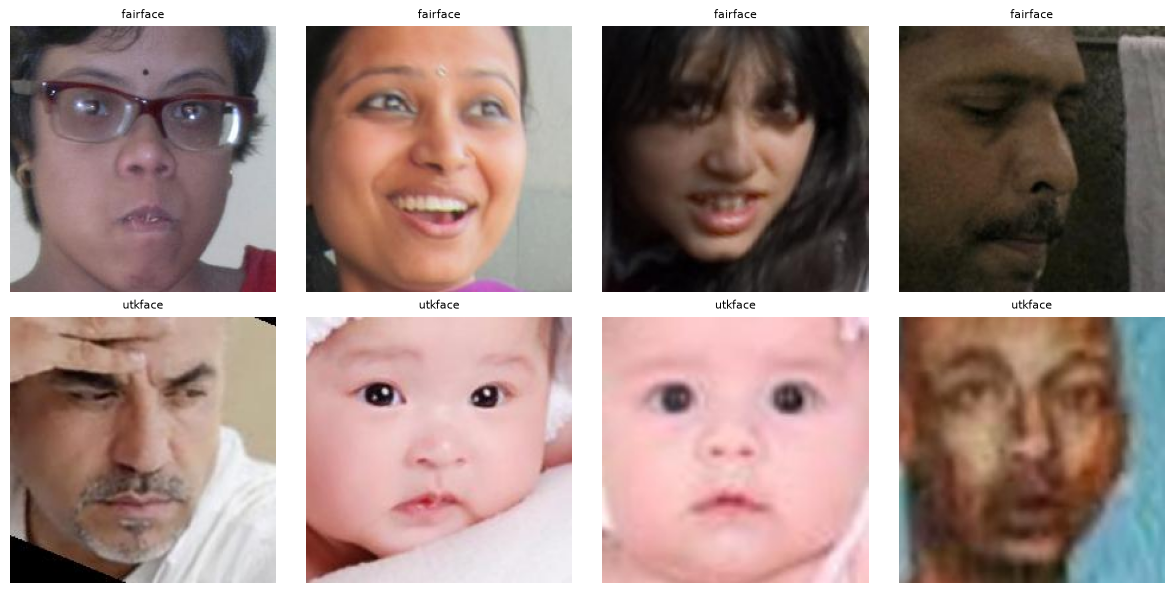

saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\qa\detector_pilot\supplied_crop_qa.png


In [42]:
fairface_sample = canonical_images_df[canonical_images_df["dataset"] == "fairface"].sample(n=50, random_state=random_seed)
utkface_sample = canonical_images_df[canonical_images_df["dataset"] == "utkface"].sample(n=50, random_state=random_seed)

for name, sample in [("fairface", fairface_sample), ("utkface", utkface_sample)]:
    sizes = set()
    for _, row in sample.iterrows():
        img = cv2.imread(str(paths.to_abs(row["path"])))
        sizes.add(img.shape[:2])
    print(f"{name}: crop sizes in sample = {sizes}")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, (_, row) in enumerate(fairface_sample.head(4).iterrows()):
    img = cv2.cvtColor(cv2.imread(str(paths.to_abs(row["path"]))), cv2.COLOR_BGR2RGB)
    axes[0, i].imshow(img)
    axes[0, i].set_title("fairface", fontsize=8)
    axes[0, i].axis("off")
for i, (_, row) in enumerate(utkface_sample.head(4).iterrows()):
    img = cv2.cvtColor(cv2.imread(str(paths.to_abs(row["path"]))), cv2.COLOR_BGR2RGB)
    axes[1, i].imshow(img)
    axes[1, i].set_title("utkface", fontsize=8)
    axes[1, i].axis("off")
plt.tight_layout()
crop_qa_path = paths.OUTPUTS_DATA_PREP_DIR / "qa" / "detector_pilot" / "supplied_crop_qa.png"
crop_qa_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(crop_qa_path, dpi=100)
plt.show()
print("saved:", crop_qa_path)


## 13. Derived Measurement Pilot

Feature engineering happens here, nowhere earlier. LFW uses our own aligned crop from section 12. FairFace and UTKFace use the supplied crop directly since no detection or alignment was applied to them, so there's no bbox to compute face_area_ratio from, the whole image counts as the face. Pose stays deferred.

In [43]:
from src import measurements

gov006 = yaml.safe_load(open(paths.CONFIGS_DIR / "GOV-006_preprocessing.yaml"))
skin_cfg = gov006["skin_measurement"]
roi_patches = skin_cfg["roi_patches"]
skin_filter = skin_cfg["roi_skin_filter"]
roi_min_valid_pixels = skin_cfg["roi_min_valid_pixels"]
b_star_min_abs = skin_cfg["ita_guard"]["b_star_min_abs"]


def measure_one(rgb, dataset, rel_path, bbox=None, orig_w=None, orig_h=None):
    row = {"path": rel_path, "dataset": dataset}
    row["brightness"] = measurements.brightness(rgb)
    row["contrast"] = measurements.contrast(rgb)
    row["sharpness"] = measurements.sharpness(rgb)

    if bbox is not None:
        row.update(measurements.face_size(bbox, orig_w, orig_h))
    else:
        row["face_bbox_area_px"] = rgb.shape[0] * rgb.shape[1]
        row["face_area_ratio"] = 1.0

    row["yaw"] = row["pitch"] = row["roll"] = None

    skin_pixels = measurements.extract_skin_roi_pixels(rgb, roi_patches, skin_filter)
    row["skin_roi_valid_pixel_count"] = len(skin_pixels)
    row["skin_roi_valid"] = len(skin_pixels) >= roi_min_valid_pixels

    if row["skin_roi_valid"]:
        lab = measurements.cielab_median(skin_pixels)
        row["L_star"], row["a_star"], row["b_star"] = lab
        ita_result = measurements.compute_ita(row["L_star"], row["b_star"], b_star_min_abs)
        row["ITA"] = ita_result["ita"]
        row["ita_undefined"] = ita_result["ita_undefined"]
        row["hue_angle"] = measurements.compute_hue(row["a_star"], row["b_star"])
    else:
        row["L_star"] = row["a_star"] = row["b_star"] = None
        row["ITA"] = None
        row["ita_undefined"] = None
        row["hue_angle"] = None
    return row


measurement_rows = []

for rel_path, aligned_rgb in aligned_crops.items():
    measurement_rows.append(measure_one(aligned_rgb, "lfw", rel_path))

for name, sample in [("fairface", fairface_sample), ("utkface", utkface_sample)]:
    for _, row in sample.iterrows():
        img_bgr = cv2.imread(str(paths.to_abs(row["path"])))
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        measurement_rows.append(measure_one(img_rgb, name, row["path"]))

measurements_df = pandas.DataFrame(measurement_rows)
measurements_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "measurements_pilot.csv"
measurements_df.to_csv(measurements_path, index=False)

print(f"measured {len(measurements_df)} pilot images")
print(measurements_df.groupby(["dataset", "skin_roi_valid"]).size())
n_ita_guard = int((measurements_df["ita_undefined"] == True).sum())
print(f"ita guard tripped: {n_ita_guard}")
print("saved:", measurements_path)


measured 150 pilot images
dataset   skin_roi_valid
fairface  True              50
lfw       False              9
          True              41
utkface   False              3
          True              47
dtype: int64
ita guard tripped: 2
saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\tables\measurements_pilot.csv


### 13.11 measurement visual qa

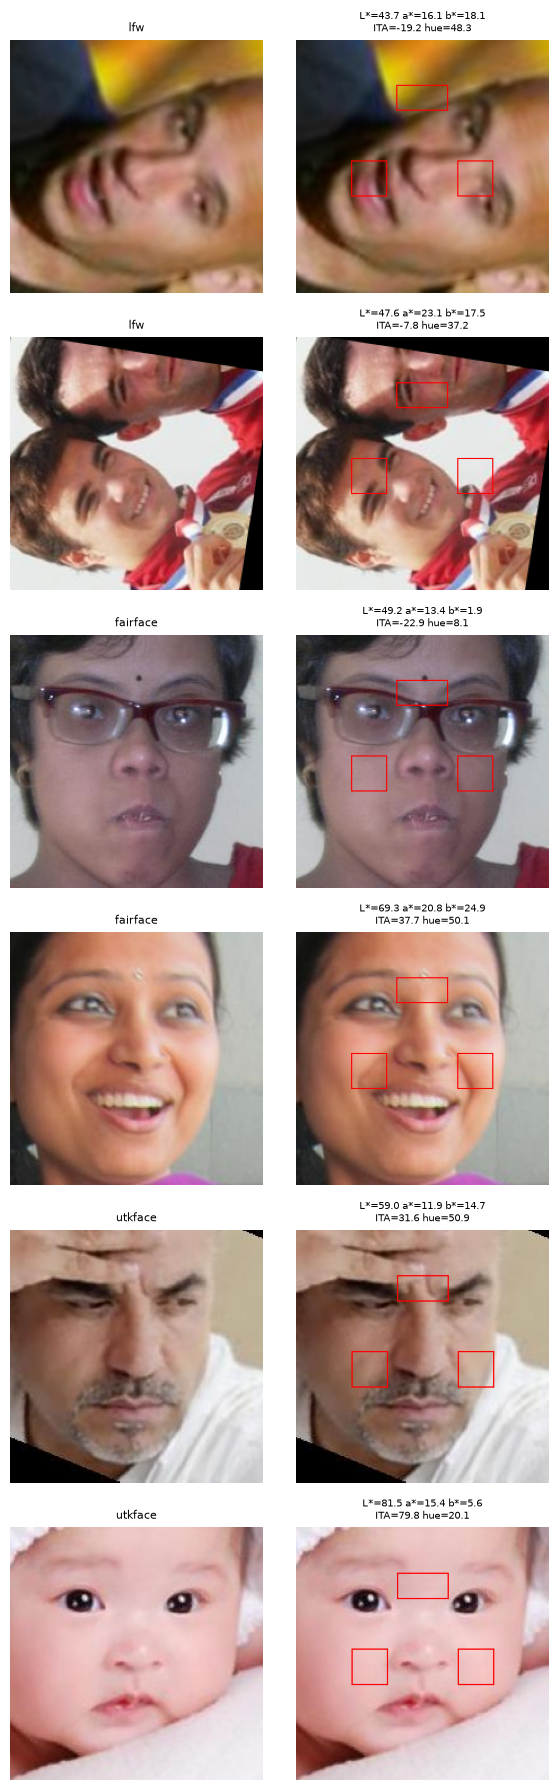

saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\qa\measurement_examples\skin_roi_qa.png


In [44]:
qa_measure_sample = measurements_df[measurements_df["skin_roi_valid"]].groupby("dataset").head(2)

fig, axes = plt.subplots(len(qa_measure_sample), 2, figsize=(6, 3 * len(qa_measure_sample)))
if len(qa_measure_sample) == 1:
    axes = axes.reshape(1, -1)

for i, (_, mrow) in enumerate(qa_measure_sample.iterrows()):
    rel_path = mrow["path"]
    if mrow["dataset"] == "lfw":
        rgb = aligned_crops[rel_path]
    else:
        rgb = cv2.cvtColor(cv2.imread(str(paths.to_abs(rel_path))), cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]

    overlay = rgb.copy()
    for patch in roi_patches.values():
        x1, y1 = int(patch["x"][0] * w), int(patch["y"][0] * h)
        x2, y2 = int(patch["x"][1] * w), int(patch["y"][1] * h)
        cv2.rectangle(overlay, (x1, y1), (x2, y2), (255, 0, 0), 1)

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(mrow["dataset"], fontsize=8)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(overlay)
    title = (
        f"L*={mrow['L_star']:.1f} a*={mrow['a_star']:.1f} b*={mrow['b_star']:.1f}\n"
        f"ITA={mrow['ITA']:.1f} hue={mrow['hue_angle']:.1f}"
    )
    axes[i, 1].set_title(title, fontsize=7)
    axes[i, 1].axis("off")

plt.tight_layout()
measurement_qa_path = paths.OUTPUTS_DATA_PREP_DIR / "qa" / "measurement_examples" / "skin_roi_qa.png"
measurement_qa_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(measurement_qa_path, dpi=100)
plt.show()
print("saved:", measurement_qa_path)


### feature sanity checks

In [45]:
numeric_cols = ["brightness", "contrast", "sharpness", "face_bbox_area_px", "face_area_ratio", "L_star", "a_star", "b_star", "ITA", "hue_angle"]
print(measurements_df[numeric_cols].describe())

problems = []
if (measurements_df["face_area_ratio"] > 1).any():
    problems.append(f"{(measurements_df['face_area_ratio'] > 1).sum()} rows with face_area_ratio > 1")
if measurements_df["sharpness"].isna().any():
    problems.append(f"{measurements_df['sharpness'].isna().sum()} rows with sharpness NaN")
valid_lab = measurements_df.dropna(subset=["L_star"])
if ((valid_lab["L_star"] < 0) | (valid_lab["L_star"] > 100)).any():
    problems.append("L_star outside the expected 0-100 range")
low_valid = measurements_df[measurements_df["skin_roi_valid_pixel_count"] < roi_min_valid_pixels]
if len(low_valid) > 0 and low_valid["skin_roi_valid"].any():
    problems.append("skin_roi_valid True despite pixel count below the minimum, check the rule")

if problems:
    print("\nproblems found:")
    for p in problems:
        print(" -", p)
else:
    print("\nno impossible values found in this pilot")

sanity_path = paths.OUTPUTS_DATA_PREP_DIR / "tables" / "measurements_pilot_sanity.csv"
measurements_df[numeric_cols].describe().to_csv(sanity_path)
print("saved:", sanity_path)


       brightness    contrast    sharpness  face_bbox_area_px  \
count  150.000000  150.000000   150.000000         150.000000   
mean   101.662926   50.002573   108.863210       46784.000000   
std     43.943973   14.344468   193.606782        4813.082842   
min      1.993107   14.739979     3.742924       40000.000000   
25%     78.598480   40.729088    18.458404       40000.000000   
50%    105.607390   49.681745    31.722620       50176.000000   
75%    132.023409   59.913354    75.854049       50176.000000   
max    197.671564   78.751246  1336.957508       50176.000000   

       face_area_ratio      L_star      a_star      b_star         ITA  \
count            150.0  138.000000  138.000000  138.000000  136.000000   
mean               1.0   53.240882   15.276169   18.151211    5.351989   
std                0.0   18.063960    5.895064    8.143886   43.310445   
min                1.0   15.988394   -4.457238    0.326615  -85.050695   
25%                1.0   39.109410   11.8336

Sections 12-13 pilot complete. Detection/alignment/measurement tables saved under `outputs/data_prep/tables/`, qa figures under `outputs/data_prep/qa/`.

**Next:** section 14, splits.

## 14. Leakage and Split Rules

In [46]:
utkface_ids = master_df.loc[master_df["dataset"] == "utkface", "image_id"].values
rng = numpy.random.default_rng(gov006["splits"]["utkface"]["seed"])
shuffled = rng.permutation(utkface_ids)

n = len(shuffled)
n_train = int(n * 0.7)
n_val = int(n * 0.15)
split_labels = ["train"] * n_train + ["val"] * n_val + ["test"] * (n - n_train - n_val)

utkface_split = pandas.DataFrame({"image_id": shuffled, "split": split_labels})
utkface_split_path = paths.PROJECT_ROOT / "metadata" / "utkface_split.csv"
utkface_split_path.parent.mkdir(parents=True, exist_ok=True)
utkface_split.to_csv(utkface_split_path, index=False)

print("utkface split saved:", utkface_split_path)
print(utkface_split["split"].value_counts())
print("\nfairface: official train/val split preserved as supplied, no changes made")
print("lfw: view1/view2 protocol comes from the original people.csv/pairs.csv, view2 stays sealed per gov-006 until final reporting")
print("cross-dataset overlap already checked in section 9.3, 0 for all three pairs, so no leakage exclusions needed here")


utkface split saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\metadata\utkface_split.csv
split
train    16595
test      3557
val       3556
Name: count, dtype: int64

fairface: official train/val split preserved as supplied, no changes made
lfw: view1/view2 protocol comes from the original people.csv/pairs.csv, view2 stays sealed per gov-006 until final reporting
cross-dataset overlap already checked in section 9.3, 0 for all three pairs, so no leakage exclusions needed here


## 16. Phase 0 Data-Ready Checklist

In [47]:
checklist = [
    ("all datasets located", True),
    ("dataset sources/versions recorded where available", True),
    ("raw image counts known", True),
    ("metadata counts known", True),
    ("metadata-image reconciliation complete", True),
    ("parsing validated", True),
    ("unexpected labels reported", True),
    ("missingness quantified", True),
    ("age-band construction validated (nesting test passed)", True),
    ("gender coding validated", True),
    ("native race categories preserved", True),
    ("image decoding completed", image_integrity_df["decode_success"].all()),
    ("image dimensions recorded", True),
    ("image modes recorded", True),
    ("exif inspected", True),
    ("colour metadata inspected", True),
    ("corrupt files flagged", True),
    ("exact duplicates checked", True),
    ("cross-dataset overlaps checked", True),
    ("stable image ids created", master_df["image_id"].is_unique),
    ("master annotation table created", True),
    ("ids confirmed unique", master_df["image_id"].is_unique),
    ("preprocessing provenance recorded per dataset", True),
    ("retinaface pilot completed on raw data (lfw)", n_success == len(detection_rows)),
    ("zero/multiple detections reviewed", True),
    ("alignment pilot completed", n_aligned > 0),
    ("visual qa completed", True),
    ("basic derived measurements pilot completed", len(measurements_df) > 0),
    ("skin roi method validated", (measurements_df["skin_roi_valid"]).any()),
    ("cielab conversion validated", measurements_df["L_star"].notna().any()),
    ("ita calculation validated", measurements_df["ITA"].notna().any()),
    ("hue calculation validated", measurements_df["hue_angle"].notna().any()),
    ("leakage rules documented", True),
    ("utkface split created", True),
    ("lfw protocol integrity checked", True),
    ("data-preparation artefacts saved", True),
]

print(f"{'item':<55}{'status'}")
for item, status in checklist:
    mark = "done" if status else "pending"
    print(f"{item:<55}{mark}")

n_done = sum(1 for _, s in checklist if s)
print(f"\n{n_done}/{len(checklist)} items done")

if n_done == len(checklist):
    final_status = "READY"
elif n_done >= len(checklist) * 0.8:
    final_status = "READY WITH WARNINGS"
else:
    final_status = "NOT READY"

print(f"\nphase 0 status: {final_status}")
print("outstanding: near-duplicate detection (9.2), pose estimation, full-scale retinaface + feature extraction on all 134,639 images")
print("these are pending on purpose, not forgotten, full-scale work goes to the wits cluster once this pilot is signed off")


item                                                   status
all datasets located                                   done
dataset sources/versions recorded where available      done
raw image counts known                                 done
metadata counts known                                  done
metadata-image reconciliation complete                 done
parsing validated                                      done
unexpected labels reported                             done
missingness quantified                                 done
age-band construction validated (nesting test passed)  done
gender coding validated                                done
native race categories preserved                       done
image decoding completed                               done
image dimensions recorded                              done
image modes recorded                                   done
exif inspected                                         done
colour metadata inspected             